# Where a coding-algorithm ban takes effect in an LLM

**Artifact:** experiment `art_8_ULPE8jJQc_`: a causal **route test (C2)** and a **compliance-at-R test (C5)** for
prompt-level algorithm bans in **Qwen/Qwen3-8B** (bf16, thinking off, Hub revision `b968826d`).

Tell an LLM *"Do not use breadth-first search (BFS) for this task."*, then ask it for a grid path-finder, and it
mostly writes DFS instead. This experiment asks **where inside the model the ban takes effect**. Does the model fold
the ban into its reading of the task description (the **prompt route**)? Or do the tokens it generates look back at
the ban sentence directly (the **direct route**)?

**Tasks** (iteration-1's canonical suite):
- **T1** grid path, `solve(grid, start, goal)`, ban **BFS**
- **T2** weighted shortest path, `solve(n, edges, s, t)`, ban **Dijkstra**

**Design.** Each of 5 frozen ban templates (W1-W5) has a **neutral twin**. The twin prohibits irrelevant nouns in the
same frame (*"Do not use man, the house and the baby for this task."*). It is padded until the chat-formatted prompt
has exactly the ban prompt's token length, with identical token ids from `Task:` (position `p1`) onward. The two
prompts' KV caches can therefore be **spliced position by position**:

| arm | condition span `[p0, p1)` | task spec + read position R, `[p1, P)` | R logits | what it isolates |
|---|---|---|---|---|
| **a** | ban | ban | ban | full ban |
| **b** | neutral | neutral | neutral | baseline (neutral twin) |
| **c** | neutral | ban | ban | **PROMPT ROUTE**: generated tokens learn about the ban only through states that already read it |
| **d** | ban | neutral | neutral | **DIRECT ROUTE**: generated tokens can only read the ban sentence itself |
| e | neutral | neutral, except R from ban | ban | R alone |
| f | neutral | ban, except R from neutral | neutral | task-spec states alone |
| K0 | ban (cache a) | ban | ban | generated tokens cannot attend to the condition span (attention knockout) |

**Primary readout** (pre-registered; the decision rule was sha256-committed before scoring): the **FRLP drop** of the
banned algorithm X. Thirty self-written, name-scrubbed X programs are teacher-forced on each arm's cache, giving
`D_X(arm) = L_X(arm) - L_X(b)`. The route fractions are `F_prompt = D(c)/D(a)` and `F_direct = D(d)/D(a)`.

**Full-run results** (Qwen3-8B, one RTX 4090, about 70 GPU-minutes):
- **C2 decision:** DECIDED BEFORE WRITING. The ban is carried by the prompt route, and this is ROBUST across both
  tasks: pooled `F_prompt = 0.85 [0.61, 1.20]`, `F_direct = 0.00 [-0.08, 0.12]`.
- **Which states carry it:** R alone carries nothing (`F_R ≈ 0`); the task-spec states carry it (`F_spec` 0.86 / 0.81).
- **Behaviour** (common random numbers, N = 100 per arm): the banned share for a / b / c / d is
  0.14 / 1.00 / 0.57 / 0.70 in T1 and 0.11 / 0.99 / 0.13 / 0.95 in T2.
- **Mechanism:** the ban suppresses the model's default first line (`from collections import deque` /
  `import heapq`), and this opening veto is fully prompt-carried.
- **C5:** within-cell Spearman of banned share against the projection of the residual at R on a shared ban direction
  is -0.41 [-0.69, -0.17], p = 0.0003. That is **PARTIAL** against the pre-registered -0.5 bar.

### What this notebook runs (CPU, under 10 minutes)
1. **`method.py`**, the experiment's stage runner, as its own cell, followed by the code of each stage it dispatches to.
2. A **live, demo-scale route test** on a **small Qwen3 model**, using the experiment's own `engine.py`, `arms.py`,
   `build_prompts.py` and `behaviour.py`. Every Qwen3 size shares one tokenizer, so the frozen Qwen3-8B prompts and
   their splice positions are reproduced token for token. The run covers:
   - S1 prompts and length-matched twins;
   - U3 engine checks;
   - S5-style teacher-forced scoring of Qwen3-8B's own BFS openings under every arm;
   - S4 common-random-number sampling of the opening line.
3. The **pre-registered S8 analysis code** (`analysis.py`) and the supplementary contrasts (`supplementary.py`),
   re-run on `mini_demo_data.json`. That file holds 100 CRN-matched Qwen3-8B behaviour samples from T1 (arms a, b, c,
   d and K0; 5 templates × 4 streams) together with the full-run reference numbers.
4. **Figures and tables** that set the demo numbers beside the full-run numbers.

The config cell lists every scale parameter next to its original value. The GPU stages at full scale need the full
repository (`round-2/experiment-8/src`) and a 24 GB GPU; see the last cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original code logs through loguru)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib, torch, transformers — pre-installed on Colab, install locally only (Colab versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0',
         'torch==2.9.0+cpu', 'transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0',
         '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
# --- method.py imports (verbatim) ---
from __future__ import annotations

import sys
import time

from loguru import logger

# --- imports of the modules method.py dispatches to (cfg, engine, arms, build_prompts, behaviour, analysis,
#     supplementary, suite/labeller/extract), copied from their headers ---
import ast
import contextlib
import gc
import hashlib
import json
import math
import os
import re
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Iterator

import numpy as np
import torch
from scipy import stats

# --- notebook additions: tables and figures ---
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-2/experiment-8/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_ex = data["datasets"][0]["examples"]
print(data["datasets"][0]["dataset"], "-", len(_ex), "Qwen3-8B behaviour samples; per arm:",
      dict(Counter(e["metadata_arm"] for e in _ex)))
print("selection:", data["metadata"]["selection"]["rule"])
print("\nexample prompt header:", _ex[0]["input"].split("\n\n")[0])
print("example label (mechanism-level labeller):", _ex[0]["output"], "| first code line:",
      _ex[0]["metadata_code"].splitlines()[0])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
T1_grid_path_ban_BFS_behaviour_crn - 100 Qwen3-8B behaviour samples; per arm: {'a': 20, 'b': 20, 'c': 20, 'd': 20, 'K0': 20}
selection: first two CRN streams of each neutral-noun half (s=0,1 noun A; s=10,11 noun B), every template, arms a/b/c/d/K0; 100 CRN-matched samples

example prompt header: [arm a: full ban (ban KV cache, ban R logits)] [template W1] [ban segment: Do not use breadth-first search (BFS) for this task.] [neutral segment: Do not use breadth-first search (BFS) for this task.]
example label (mechanism-level labeller): dfs | first code line: def solve(grid, start, goal):


## Configuration

Every scale parameter is set here, with the original value in the comment beside it.

**Live part.** The original runs Qwen3-8B in bf16 on a 24 GB GPU. On a CPU we use a small model from the same
family. Qwen3 models share one tokenizer and chat template, so the prompts, positions `p0`/`p1` and splices are
identical; only the network is smaller. The minimum setting is Qwen3-0.6B. Qwen3-1.7B is the first size that
reproduces the opening-line effect (import line under the neutral twin, `def solve` under the ban).

**Analysis part.** The bootstrap size of `analysis.behaviour()`. It is vectorised, so the original 2,000 replicates
take well under a second.

In [5]:
# ---------------- live KV-splice demo: S1 prompts, S3 engine, U3 checks, S5 scoring, S4 CRN sampling ----------------
RUN_LIVE_MODEL = True              # False skips the model part; the S8 analysis of the stored Qwen3-8B samples still runs
MODEL_ID = "Qwen/Qwen3-1.7B"          # original: "Qwen/Qwen3-8B" (bf16, one 24 GB GPU); same tokenizer for every Qwen3 size
DTYPE = "float32"                  # original: "bfloat16" on GPU (float32 is the safe CPU / T4 choice)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LIVE_TASK = "t1"                   # T1 grid path, ban BFS (the task stored in mini_demo_data.json); original: t1 and t2
LIVE_TEMPLATES = ["W1"]              # original: ["W1", "W2", "W3", "W4", "W5"]
LIVE_STREAMS = [0, 10, 1, 11]                 # CRN streams per template (s < 10: neutral noun A, s >= 10: noun B); original: 0..19
LIVE_ARMS = ("a", "b", "c", "d", "e", "f", "K0")   # teacher-forced arms (original FRLP also: pl, K1, K2, B1-B3, K0b, mention)
LIVE_SAMPLE_ARMS = ("a", "b", "c", "d", "K0")      # CRN-sampled arms (original S4: a-d, K1, K2; supplementary: K0)
N_SCORE_PROGRAMS = 4          # Qwen3-8B arm-b BFS programs scored per template (<= 4 stored); original: 30 forced programs
N_SCORE_TOKENS = 24           # leading tokens scored per program; original: the whole program (~300 tokens)
N_NEW_TOKENS = 12              # tokens sampled per CRN stream (enough for the first code line); original: 1024

# ---------------- S8 analysis of the stored Qwen3-8B behaviour samples ----------------------------------------------
N_BOOT_BEH = 2000              # paired CRN bootstrap replicates in analysis.behaviour(); original: 2000

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # notebook: quieter downloads
print(f"live model {MODEL_ID} on {DEVICE} ({DTYPE}); templates {LIVE_TEMPLATES}; streams {LIVE_STREAMS}; "
      f"{N_SCORE_PROGRAMS} programs x {N_SCORE_TOKENS} tokens scored; {N_NEW_TOKENS} tokens sampled")

live model Qwen/Qwen3-1.7B on cpu (float32); templates ['W1']; streams [0, 10, 1, 11]; 4 programs x 24 tokens scored; 12 tokens sampled


## `cfg.py`: the frozen protocol, shared by every stage

`cfg.py` holds everything the plan froze: display names, the ban / mention / neutral templates W1-W5, signature
vocabularies, decision thresholds and bootstrap sizes, plus small utilities (seeded streams, JSON I/O, Wilson
intervals, chat formatting). The pre-registration hashes this protocol, so every stage reads one source.

Notebook changes, all marked in the code:
- `ROOT` is a local folder; there is no `__file__`.
- `MODEL_ID` and `MAX_NEW_TOKENS` come from the config cell.
- `spec_text()` reads the canonical task text from the stored prompts instead of the snapshotted `conditions.json`.
- `chat_ids()` also accepts the `BatchEncoding` that transformers 5 returns.

Left out because nothing here uses them: the upstream-artifact paths (S0), the forced-prompt paraphrases (S2) and the
RAM/CPU helpers.

In [6]:
# cfg.py (subset, verbatim unless marked)
ROOT = Path("ban_route_demo_run").resolve()  # notebook: the original anchors on Path(__file__).resolve().parent
PROMPTS_DIR = ROOT / "prompts"
DATA_DIR = ROOT / "data"
TOKEN_LP_DIR = DATA_DIR / "token_lp"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
WORK_DIR = ROOT / "work"
for _d in (PROMPTS_DIR, DATA_DIR, TOKEN_LP_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, WORK_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ model
# notebook: MODEL_ID is set in the config cell; the revision pin belongs to the Qwen3-8B snapshot
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218" if MODEL_ID == "Qwen/Qwen3-8B" else "main"


def model_path() -> str:
    """BRT_MODEL_PATH (a local copy of the pinned snapshot) if set; else that snapshot inside the Hugging Face cache
    named by HF_HUB_CACHE if it is complete; else the Hub id (loaded at MODEL_REVISION, see hf_kwargs)."""
    env = os.environ.get("BRT_MODEL_PATH")
    if env:
        return env
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + MODEL_ID.replace("/", "--")) / "snapshots" / MODEL_REVISION  # notebook
        if all((snap / f"model-0000{i}-of-00005.safetensors").exists() for i in range(1, 6)):
            return str(snap)
    return MODEL_ID


def hf_kwargs() -> dict[str, str]:
    """Pin the Hub revision whenever the model is loaded by id."""
    return {"revision": MODEL_REVISION} if model_path() == MODEL_ID else {}


def model_revision() -> str:
    return MODEL_REVISION


N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = N_NEW_TOKENS  # notebook: from the config cell (original: 1024)
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"

# ------------------------------------------------------------------------------------------------ tasks
TASKS = ("t1", "t2")
X_KEY = {"t1": "bfs", "t2": "dijkstra"}
SUB_KEY = {"t1": "dfs", "t2": "bf_spfa"}  # the dominant substitute in iteration 1
DISPLAY: dict[str, dict[str, str]] = {
    "t1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bibfs": "bidirectional BFS",
        "iddfs": "iterative deepening DFS (IDDFS)",
        "astar_gbfs": "A* search",
        "dijkstra": "unit-weight Dijkstra",
    },
    "t2": {
        "dijkstra": "Dijkstra's algorithm",
        "bf_spfa": "Bellman-Ford or SPFA",
        "bidijkstra": "bidirectional Dijkstra",
        "floyd": "Floyd-Warshall",
        "dial": "Dial's bucket-queue algorithm",
    },
}
ALGOS = {t: list(DISPLAY[t].keys()) for t in TASKS}
SURVIVORS = {t: [a for a in ALGOS[t] if a != X_KEY[t]] for t in TASKS}

# W1-W5: (ban, mention, neutral) verbatim from the shared protocol v2.
TEMPLATES: dict[str, tuple[str, str, str]] = {
    "W1": ("Do not use {X} for this task.", "You could use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution may rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Consider {X} first.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{X} is allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that may use {X}.",
           "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES.keys())

# Signature vocabularies (frozen). Used only for per-token localisation and the lens.
SIGNATURE_VOCAB: dict[str, list[str]] = {
    "bfs": ["deque", "popleft", "collections"],
    "dfs": ["stack", "pop()", "setrecursionlimit"],
    "dijkstra": ["heapq", "heappush", "heappop", "heapify"],
    "astar_gbfs": ["heapq", "heuristic", "abs("],
    "bf_spfa": ["deque", "popleft", "in_queue", "inq", "range(n - 1)"],
}
SUBSTITUTE_VOCAB_KEY = {"t1": "dfs", "t2": "bf_spfa"}

# Catalogue-name scrub regex (case-insensitive), frozen.
SCRUB_REGEX = (r"bfs|breadth|dfs|depth[-_ ]?first|dijkstra|bellman|ford|spfa|floyd|warshall|dial|bucket[-_ ]?queue|"
               r"a\*|astar|a_star|best[-_ ]?first|greedy|bidirectional|bi_?bfs|iddfs|iterative[-_ ]?deepening")

# ------------------------------------------------------------------------------------------------ arms
MAIN_ARMS = ("a", "b", "c", "d")
X_ONLY_ARMS = ("e", "f", "pl", "K0", "K1", "K2", "B1", "B2", "B3", "K0b")
KO_WINDOW = 16
LAYER_BANDS = {"B1": list(range(0, 12)), "B2": list(range(12, 24)), "B3": list(range(24, 36))}
N_PROGRAMS = 30
BEH_PER_TEMPLATE = 20
LENS_LAYERS = list(range(0, N_LAYERS + 1))
C5_LAYERS = list(range(8, 29))

THRESHOLDS = {
    "F_confirm": 2.0 / 3.0,
    "F_ci_lower": 0.5,
    "placebo_max_frac": 0.20,
    "ess_flag": 5.0,
    "c5_rho": -0.5,
    "c5_alpha": 0.05,
    "gate_avoidance": 0.5,
    "gate_min_nonbanned": 20,
    "crn_floor_min": 0.95,
    "veto_log_rank": 1.0,
}
N_BOOT = 2000
N_PERM_C5 = 10000
N_RANDOM_DIRS = 200
JUDGE_MODEL = "openai/gpt-4.1-mini"
JUDGE_CAP_USD = 0.5


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    if not Path(p).exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")


def _json_default(o: Any) -> Any:
    try:
        import numpy as np

        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return None if not np.isfinite(o) else float(o)
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.bool_):
            return bool(o)
    except ImportError:
        pass
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(obj), indent=indent, default=_json_default))
    tmp.replace(p)


def _finite(o: Any) -> Any:
    """Replace NaN/inf floats with None so the JSON stays standard."""
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def cap_first(s: str) -> str:
    return s[:1].upper() + s[1:] if s else s


def spec_text(task: str) -> str:
    """Canonical exp1 SPEC (DESCRIPTION + blank line + FORMAT), read from the snapshotted conditions.json."""
    # notebook: recovered from the stored prompts (input = header, blank line, cap_first(segment), blank line, SPEC);
    # the original reads the snapshotted inputs/iter1/exp1/prompts/conditions.json
    for e in data["datasets"][0]["examples"]:
        if e["metadata_task"] == task:
            return e["input"].split("\n\n", 1)[1].split("\n\n", 1)[1]
    raise KeyError(task)


def user_prompt(segment: str, task: str) -> str:
    """exp1 rule: [condition segment, first character upper-cased] + blank line + [SPEC]."""
    return cap_first(segment) + "\n\n" + spec_text(task)


TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"


def chat_ids(tok: Any, user_text: str) -> list[int]:
    ids = tok.apply_chat_template([{"role": "user", "content": user_text}], tokenize=True,
                                  add_generation_prompt=True, enable_thinking=False)
    if isinstance(ids, dict) or hasattr(ids, "keys"):  # notebook: transformers 5 returns a BatchEncoding
        ids = ids["input_ids"]
    return list(ids)


def chat_text(tok: Any, user_text: str) -> str:
    return tok.apply_chat_template([{"role": "user", "content": user_text}], tokenize=False,
                                   add_generation_prompt=True, enable_thinking=False)

## `method.py`: the stage runner

```
Where an algorithm ban takes effect: KV-cache splice route test (C2) + compliance-at-R test (C5) on Qwen3-8B.

Entry point. Each stage is a subcommand so GPU stages run as separate processes (vLLM and HF never share one):

  uv run method.py s0        # snapshot iteration-1 inputs, suite copy, labeller re-check
  uv run method.py s1        # frozen prompts, neutral twins, length matching, forced prompts
  uv run method.py s2        # FRLP programs (HF sampler, fallback F2), labelling, name scrub
  uv run method.py prereg    # hash-commit decision rules + frozen prompts + analysis.py BEFORE any arm is scored
  uv run method.py tests     # U0-U9 engine/sampler/knockout/analysis tests (results/tests.json)
  uv run method.py s4        # behaviour, common random numbers (HF)
  uv run method.py s4label   # canonical labeller on the behaviour samples (CPU)
  uv run method.py s5        # FRLP scoring of every arm (HF)
  uv run method.py s6        # logit lens (+ tuned lens) at the commitment token
  uv run method.py s7        # C5: compliance at R across iteration-1 wordings
  uv run method.py s8        # analysis + frozen decision (analysis.py)
  uv run method.py s9        # method_out.json, figures
```

`method.py` only dispatches. Each stage is a subcommand, so GPU stages run as separate processes, and `_time()`
logs every stage's runtime to `results/stage_times.jsonl`. The cell below is the file itself, verbatim; only the
`from cfg import ...` line is gone (the cfg cell defines those names) and the `__main__` call is commented out.

In the repository each stage lazily imports its module (`from behaviour import stage_behaviour`, ...). In this
notebook those modules' functions are defined in the following cells, and each stage is run at demo scale through the
same `_time()` helper. The full-run times are reproduced here:

| stage | what | full run (RTX 4090) |
|---|---|---|
| s0 / s1 | snapshot + labeller re-check; frozen prompts and twins | 0.8 / 1.6 min (CPU) |
| s2 | 323 forced programs (HF sampler), labelling, name scrub | 22 min |
| tests | U0-U9 gate (U3 engine equivalence, U4 knockout mass, U5 CRN determinism, ...) | 2.8 min |
| s4 | behaviour, 100 CRN samples per arm per task | 14.9 min |
| s5 | FRLP scoring of every arm (1,095 cells) | 14.5 min |
| s6 / s7 | logit / tuned lens; C5 residuals at R | 4.7 / 3.1 min |
| s8 / s9 | analysis and frozen decision; `method_out.json` and figures | 1.3 / 0.3 min |

In [7]:
STAGE_LOG = RESULTS_DIR / "stage_times.jsonl"


def _time(stage: str, fn) -> None:
    t0 = time.time()
    logger.info(f"=== stage {stage} start")
    fn()
    dt = time.time() - t0
    append_jsonl(STAGE_LOG, [{"stage": stage, "seconds": round(dt, 1), "utc": utc_now()}])
    logger.info(f"=== stage {stage} done in {dt / 60:.1f} min")


def s0() -> None:
    from snapshot import stage_labeller_recheck, stage_snapshot

    snap = stage_snapshot()
    write_json(RESULTS_DIR / "snapshot.json", snap)
    stage_labeller_recheck()


def s1() -> None:
    from build_prompts import stage_prompts

    stage_prompts()


def s2() -> None:
    from gen_programs import stage_programs

    stage_programs()


def prereg() -> None:
    from build_prompts import stage_prereg

    stage_prereg()


def tests() -> None:
    from tests.run_tests import run_all

    res = run_all()
    critical = {
        "U3 splice identity": all(v["splice_ban_ban_identical"] and v["splice_neu_neu_identical"]
                                  for v in res["U3"].values()),
        "U3 empty-span KO": all(v["empty_ok"] for v in res["U3"].values()),
        "U3 prefill vs single pass (<0.05 nats)": all(max(v["prefill_vs_single_pass_mean_abs"]) < 0.05
                                                      for v in res["U3"].values()),
        "U4 blocked mass": res["U4"].get("blocked_ok", False),
        "U2 alignment": res["U2"]["all_ok"],
    }
    res["critical"] = critical
    write_json(RESULTS_DIR / "tests.json", res)
    bad = [k for k, v in critical.items() if not v]
    if bad:
        raise RuntimeError(f"critical tests failed: {bad}")
    logger.info(f"critical tests passed: {critical}")


def s4() -> None:
    from behaviour import stage_behaviour

    stage_behaviour()


def s4label() -> None:
    from behaviour import stage_label_behaviour

    stage_label_behaviour()


def s5() -> None:
    from frlp import stage_frlp

    stage_frlp()


def s6() -> None:
    from lens import stage_lens

    stage_lens()


def s7() -> None:
    from c5 import stage_c5

    stage_c5()


def s8() -> None:
    from analysis import stage_analysis

    stage_analysis()


def s9() -> None:
    from outputs import stage_outputs

    stage_outputs()


STAGES = {"s0": s0, "s1": s1, "s2": s2, "prereg": prereg, "tests": tests, "s4": s4, "s4label": s4label, "s5": s5,
          "s6": s6, "s7": s7,
          "s8": s8, "s9": s9}


@logger.catch(reraise=True)
def main() -> None:
    args = sys.argv[1:] or ["s8", "s9"]
    for a in args:
        if a not in STAGES:
            raise SystemExit(f"unknown stage {a}; choose from {list(STAGES)}")
    setup_logging("method_" + "_".join(args))
    for a in args:
        _time(a, STAGES[a])


# if __name__ == "__main__":   # notebook: not called; the stages are run one by one below at demo scale
#     main()


setup_logging("method_demo")  # notebook: main() does this with "method_" + the stage names
logger.info(f"demo outputs under ./{ROOT.name}/")

06:02:38|INFO   |demo outputs under ./ban_route_demo_run/


## S1 · Frozen prompts and length-matched neutral twins (`build_prompts.py`)

The **ban** prompt is `cap_first(template.replace("{X}", display name)) + blank line + SPEC`, chat-formatted with
thinking off. `_positions()` finds:
- `p0`, the first token after `<|im_start|>user\n`;
- `p1`, the first token of `Task:`, where the shared SPEC and template tail begin.

The **neutral twin** fills the same prohibition frame with an irrelevant concrete noun (`man`, twin B `guy`). It
pads the object phrase with companion nouns (`PAD_FORMS`, fewest companions first) until the twin has exactly the
ban prompt's length and identical ids at every position `>= p1`, differing only inside `[p0, p1)`.

The cell re-runs the original `_prompt_record` / `_match_neutral` with the live model's tokenizer and checks every
record against the frozen Qwen3-8B prompts stored in `mini_demo_data.json` (sha256 of the token ids).

In [8]:
# build_prompts.py (subset, verbatim)
PAD_FORMS: list[tuple[int, str]] = [
    (0, "{N}"),
    (0, "the {N}"),
    (1, "{N} and {C1}"),
    (1, "{N} and the {C1}"),
    (1, "the {N} and the {C1}"),
    (2, "{N}, {C1} and {C2}"),
    (2, "{N}, the {C1} and {C2}"),
    (2, "{N}, the {C1} and the {C2}"),
    (2, "the {N}, the {C1} and the {C2}"),
    (3, "{N}, the {C1}, the {C2} and {C3}"),
    (3, "{N}, the {C1}, the {C2} and the {C3}"),
    (3, "the {N}, the {C1}, the {C2} and the {C3}"),
]


def load_tokenizer():
    from transformers import AutoTokenizer

    return AutoTokenizer.from_pretrained(model_path(), **hf_kwargs())


def _positions(tok, ids: list[int], task: str) -> tuple[int, int]:
    head = tok("<|im_start|>user\n", add_special_tokens=False)["input_ids"]
    assert ids[:len(head)] == head, "unexpected chat header"
    suf = tok(spec_text(task) + TEMPLATE_TAIL, add_special_tokens=False)["input_ids"]
    p1 = len(ids) - len(suf)
    assert ids[p1:] == suf, "SPEC + template tail do not tokenize identically in context"
    return len(head), p1


def _prompt_record(tok, segment: str, task: str) -> dict[str, Any]:
    text = user_prompt(segment, task)
    ids = chat_ids(tok, text)
    p0, p1 = _positions(tok, ids, task)
    return {"segment": cap_first(segment), "user_text": text, "ids": ids, "P": len(ids), "p0": p0, "p1": p1,
            "ids_sha256": sha256_text(json.dumps(ids))}


def _match_neutral(tok, task: str, w: str, ban: dict[str, Any], noun: str, comps: list[str]) -> dict[str, Any] | None:
    neutral_t = TEMPLATES[w][2]
    for k, form in PAD_FORMS:
        phrase = form.format(N=noun, C1=comps[0], C2=comps[1], C3=comps[2])
        rec = _prompt_record(tok, neutral_t.replace("{N}", phrase), task)
        if rec["P"] != ban["P"] or rec["p1"] != ban["p1"] or rec["p0"] != ban["p0"]:
            continue
        if rec["ids"][rec["p1"]:] != ban["ids"][ban["p1"]:]:
            continue
        diff = [i for i, (a, b) in enumerate(zip(rec["ids"], ban["ids"])) if a != b]
        if not diff or min(diff) < ban["p0"] or max(diff) >= ban["p1"]:
            continue
        rec.update({"noun": noun, "phrase": phrase, "n_companions": k, "form": form,
                    "diff_span": [min(diff), max(diff) + 1], "n_diff_positions": len(diff)})
        return rec
    return None


# notebook: demo-scale S1 for the live task and templates (the original stage_prompts also builds the mention twins,
# the forced prompts of every algorithm and the signature-token sets, and picks the nouns from 718 candidates)
def stage_prompts_demo() -> dict[str, Any]:
    tok = load_tokenizer()
    task = LIVE_TASK
    x = X_KEY[task]
    xname = DISPLAY[task][x]
    nouns = data["metadata"]["nouns_t1"]          # frozen choice: A = 'man', B = 'guy', companions house / baby / car
    frozen = data["metadata"]["frozen_prompts_t1"]
    out = {"tasks": {task: {"x": x, "x_display": xname, "templates": {}, "nouns": nouns}}, "checks": []}
    for w in LIVE_TEMPLATES:
        ban = _prompt_record(tok, TEMPLATES[w][0].replace("{X}", xname), task)
        nA = _match_neutral(tok, task, w, ban, nouns["A"]["noun"], nouns["A"]["companions"])
        nB = _match_neutral(tok, task, w, ban, nouns["B"]["noun"], nouns["B"]["companions"])
        out["tasks"][task]["templates"][w] = {"ban": ban, "neutral_A": nA, "neutral_B": nB}
        for k, rec in (("ban", ban), ("neutral_A", nA), ("neutral_B", nB)):
            same = rec["ids_sha256"] == frozen[w][k]["ids_sha256"]
            out["checks"].append(same)
            logger.info(f"[{task} {w}] {k:9s} P={rec['P']} p0={rec['p0']} p1={rec['p1']}  {rec['segment']!r}  "
                        f"identical ids to the frozen Qwen3-8B prompt: {same}")
    return out


FP: dict[str, Any] = {}
_time("s1", lambda: FP.update(stage_prompts_demo()))
print("all re-tokenised prompts identical to the frozen Qwen3-8B prompts:", all(FP["checks"]))

06:02:38|INFO   |=== stage s1 start


06:02:41|INFO   |[t1 W1] ban       P=246 p0=3 p1=17  'Do not use breadth-first search (BFS) for this task.'  identical ids to the frozen Qwen3-8B prompt: True


06:02:41|INFO   |[t1 W1] neutral_A P=246 p0=3 p1=17  'Do not use man, the house and the baby for this task.'  identical ids to the frozen Qwen3-8B prompt: True


06:02:41|INFO   |[t1 W1] neutral_B P=246 p0=3 p1=17  'Do not use guy, the house and the baby for this task.'  identical ids to the frozen Qwen3-8B prompt: True


06:02:41|INFO   |=== stage s1 done in 0.1 min


all re-tokenised prompts identical to the frozen Qwen3-8B prompts: True


## S3 · The engine (`engine.py`), part 1: knockout-capable attention

```
S3 HF engine: Qwen3-8B bf16 with a knockout-capable SDPA attention ('ko_sdpa'), prompt prefill, KV-cache
splicing, teacher-forced scoring and a common-random-numbers (inverse-CDF) sampler.

Knockout: a global KO config names blocked key columns [p0, p1), a generated-index window [g_lo, g_hi) for the
query rows (g = absolute query position - P) and a layer set. When active for module.layer_idx the attention mask
is causal AND NOT (blocked column AND query in window); otherwise stock SDPA runs unchanged. The matching mask
function (sdpa_mask) is registered under the same name so stock causal masking is preserved.
```

`ko_sdpa` is registered as a transformers attention implementation. A global `KO` config names the blocked key
columns `[p0, p1)` (the condition span), a window of generated query indices `[g_lo, g_hi)` and a layer set. When it
is active, the mask is *causal AND NOT (blocked column AND query in window)*; otherwise stock SDPA runs unchanged.
The **K0** arm blocks all generated tokens from the span in every layer; K1/K2 split at generated index 16; B1-B3
restrict the knockout to layer bands.

Notebook change: `load_model` takes dtype and device from the config cell and uses `.to(DEVICE)` instead of
`device_map={"": 0}`, which would need `accelerate` and a GPU.

In [9]:
# engine.py (verbatim unless marked)
KO: dict[str, Any] = {"active": False, "p0": 0, "p1": 0, "P": 0, "g_lo": 0, "g_hi": 10 ** 9, "layers": None}
RECORD: dict[str, Any] = {"on": False, "weights": {}}
_REGISTERED = False


def _ko_on(module: Any) -> bool:
    return bool(KO["active"]) and (KO["layers"] is None or module.layer_idx in KO["layers"])


def _ko_allowed(q_len: int, k_len: int, device: torch.device) -> torch.Tensor:
    offset = k_len - q_len
    qpos = torch.arange(offset, k_len, device=device)
    kpos = torch.arange(k_len, device=device)
    allowed = kpos[None, :] <= qpos[:, None]
    g = qpos - int(KO["P"])
    qblock = (g >= int(KO["g_lo"])) & (g < int(KO["g_hi"]))
    kblock = (kpos >= int(KO["p0"])) & (kpos < int(KO["p1"]))
    return allowed & ~(qblock[:, None] & kblock[None, :])


def _combine(allowed: torch.Tensor, attention_mask: torch.Tensor | None, k_len: int) -> torch.Tensor:
    allowed = allowed[None, None]
    if attention_mask is not None:
        am = attention_mask[:, :, :, :k_len]
        if am.dtype == torch.bool:
            allowed = allowed & am
        else:
            allowed = allowed & (am == 0)
    return allowed


def ko_sdpa(module, query, key, value, attention_mask, **kwargs):
    from transformers.integrations.sdpa_attention import sdpa_attention_forward

    if _ko_on(module):
        q_len, k_len = query.shape[2], key.shape[2]
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
        kwargs.pop("is_causal", None)
        return sdpa_attention_forward(module, query, key, value, allowed, is_causal=False, **kwargs)
    return sdpa_attention_forward(module, query, key, value, attention_mask, **kwargs)


def ko_eager(module, query, key, value, attention_mask, **kwargs):
    """Eager twin used only by the knockout-correctness test (U4); records attention probabilities."""
    from transformers.models.qwen3.modeling_qwen3 import eager_attention_forward

    q_len, k_len = query.shape[2], key.shape[2]
    if _ko_on(module):
        allowed = _combine(_ko_allowed(q_len, k_len, query.device), attention_mask, k_len)
    else:
        base = torch.ones(q_len, k_len, dtype=torch.bool, device=query.device).tril(k_len - q_len)
        allowed = _combine(base, attention_mask, k_len)
    fmask = torch.zeros(allowed.shape, dtype=query.dtype, device=query.device)
    fmask = fmask.masked_fill(~allowed, torch.finfo(query.dtype).min)
    out, w = eager_attention_forward(module, query, key, value, fmask, **kwargs)
    if RECORD["on"]:
        RECORD["weights"][module.layer_idx] = w.detach().float().cpu()
    return out, w


def register() -> None:
    global _REGISTERED
    if _REGISTERED:
        return
    from transformers import AttentionInterface
    from transformers.masking_utils import AttentionMaskInterface, eager_mask, sdpa_mask

    AttentionInterface.register("ko_sdpa", ko_sdpa)
    AttentionInterface.register("ko_eager", ko_eager)
    AttentionMaskInterface.register("ko_sdpa", sdpa_mask)
    AttentionMaskInterface.register("ko_eager", eager_mask)
    _REGISTERED = True


@contextlib.contextmanager
def knockout(cfg: dict[str, Any] | None) -> Iterator[None]:
    """cfg: {'p0','p1','P','g_lo','g_hi','layers'} or None (no knockout)."""
    old = dict(KO)
    try:
        if cfg is not None:
            KO.update({"active": True, "g_lo": 0, "g_hi": 10 ** 9, "layers": None})
            KO.update(cfg)
        else:
            KO["active"] = False
        yield
    finally:
        KO.clear()
        KO.update(old)


def set_attn(model: Any, name: str) -> None:
    model.config._attn_implementation = name
    for m in model.modules():
        if hasattr(m, "config") and m.config is not model.config and hasattr(m.config, "_attn_implementation"):
            m.config._attn_implementation = name


def load_model(vram_fraction: float = 0.95):
    from transformers import AutoModelForCausalLM, AutoTokenizer

    register()
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(model_path(), **hf_kwargs())
    # notebook: dtype / device from the config cell; .to(DEVICE) instead of device_map={"": 0} (no accelerate needed)
    model = AutoModelForCausalLM.from_pretrained(model_path(), dtype=getattr(torch, DTYPE), attn_implementation="ko_sdpa",
                                                 **hf_kwargs()).to(DEVICE)
    model.eval()
    if DEVICE == "cuda":
        torch.cuda.set_per_process_memory_fraction(vram_fraction, 0)
        free, total = torch.cuda.mem_get_info(0)
        logger.info(f"HF model loaded in {time.time() - t0:.0f}s; attn={model.config._attn_implementation}; "
                    f"free VRAM {free / 1e9:.1f}/{total / 1e9:.1f} GB")
    else:
        logger.info(f"HF model loaded in {time.time() - t0:.0f}s; attn={model.config._attn_implementation}; cpu")
    return tok, model

### Engine, part 2: prefill and KV-cache splicing

- `prefill` runs the prompt once and keeps the per-layer `(K, V)` cache plus the logits at the read position R
  (the last prompt token).
- `splice(kv_a, kv_b, cut)` takes positions `[0, cut)` from A and `[cut, P)` from B in every layer.
- `replace_positions` swaps chosen positions; arms e and f use it for R alone.

Because the twins have identical ids from `p1` on, a spliced cache is a valid cache for the shared continuation.

In [10]:
# engine.py (verbatim)
def _kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


def build_cache(kv: list[tuple[torch.Tensor, torch.Tensor]], batch: int = 1):
    from transformers.cache_utils import DynamicCache

    cache = DynamicCache()
    for l, (K, V) in enumerate(kv):
        if K.shape[0] != batch:
            K = K.expand(batch, -1, -1, -1)
            V = V.expand(batch, -1, -1, -1)
        cache.update(K.contiguous(), V.contiguous(), l)
    return cache


@torch.no_grad()
def prefill(model: Any, ids: list[int], hidden_layers: list[int] | None = None) -> dict[str, Any]:
    """Returns {'kv': per-layer (K, V) [1, 8, P, 128] on GPU, 'r_logits': float32 [V], 'P', 'hR': {l: float32}}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=model.device)
    cache = DynamicCache()
    out = model.model(input_ids=inp, past_key_values=cache, use_cache=True,
                      output_hidden_states=hidden_layers is not None)
    r_logits = model.lm_head(out.last_hidden_state[:, -1]).float()[0]
    kv = [(K.clone(), V.clone()) for K, V in _kv_list(cache)]
    res = {"kv": kv, "r_logits": r_logits, "P": len(ids)}
    if hidden_layers is not None:
        res["hR"] = {l: out.hidden_states[l][0, -1].float().cpu().numpy() for l in hidden_layers}
    del cache, out
    return res


def splice(kv_a: list, kv_b: list, cut: int) -> list:
    """Positions [0, cut) from A and [cut, P) from B, every layer."""
    return [(torch.cat([Ka[:, :, :cut], Kb[:, :, cut:]], dim=2), torch.cat([Va[:, :, :cut], Vb[:, :, cut:]], dim=2))
            for (Ka, Va), (Kb, Vb) in zip(kv_a, kv_b)]


def replace_positions(kv_base: list, kv_src: list, positions: list[int]) -> list:
    out = []
    idx = torch.tensor(positions, device=kv_base[0][0].device)
    for (Kb, Vb), (Ks, Vs) in zip(kv_base, kv_src):
        K, V = Kb.clone(), Vb.clone()
        K[:, :, idx] = Ks[:, :, idx]
        V[:, :, idx] = Vs[:, :, idx]
        out.append((K, V))
    return out

### Engine, part 3: teacher-forced scoring and the common-random-numbers sampler

- `score` places each token sequence after an arm's cache. Token 0 is scored with the arm's R logits; token
  `t >= 1` with the hidden state at `P + t - 1`. It runs at batch 1, so a program's score depends only on the cache
  content.
- `sample` draws by **inverse CDF**: one shared uniform per (row, step), and the token is the first vocabulary index
  whose CDF reaches `u`. `u_stream(*key)` gives each (task, template, stream) one PCG64 stream that every arm reuses.
  Arms then differ only through their caches, and paired comparisons are exact (common random numbers).

Notebook change: `u_stream` gets `stable_seed` from the cfg cell rather than importing it.

In [11]:
# engine.py (verbatim unless marked)
@torch.no_grad()
def _token_logprobs(model: Any, h: torch.Tensor, tgt: torch.Tensor, chunk: int = 256) -> torch.Tensor:
    out = []
    for i in range(0, h.shape[0], chunk):
        logits = model.lm_head(h[i:i + chunk]).float()
        out.append(torch.log_softmax(logits, dim=-1).gather(-1, tgt[i:i + chunk, None])[:, 0])
    return torch.cat(out) if out else torch.zeros(0, device=h.device)


@torch.no_grad()
def score(model: Any, arm: dict[str, Any], seqs: list[list[int]], ko: dict[str, Any] | None = None,
          token_budget: int = 9000, max_batch: int = 1) -> list[np.ndarray]:
    """Teacher-forced per-token log-probs of each token sequence placed after the arm's prompt cache.
    Token 0 is scored with the arm's R logits; token t >= 1 with the hidden state at position P + t - 1.
    Default batch 1: a program's score then depends only on the cache content (identical GEMM/attention shapes in
    every arm of a template), never on which other programs share its batch (bf16 kernel choice is shape-dependent)."""
    kv, r_logits = arm["kv"], arm["r_logits"]
    P = kv[0][0].shape[2]
    r_lp = torch.log_softmax(r_logits.float(), dim=-1)
    order = sorted(range(len(seqs)), key=lambda i: -len(seqs[i]))
    res: list[np.ndarray | None] = [None] * len(seqs)
    i = 0
    bs = max_batch
    while i < len(order):
        T = len(seqs[order[i]])
        b = max(1, min(bs, token_budget // max(T, 1), len(order) - i))
        idxs = order[i:i + b]
        try:
            inp = torch.full((b, T), IM_END, dtype=torch.long, device=model.device)
            for r, k in enumerate(idxs):
                inp[r, :len(seqs[k])] = torch.tensor(seqs[k], device=model.device)
            cache = build_cache(kv, b)
            pos = torch.arange(P, P + T, device=model.device)[None].expand(b, -1)
            kcfg = None if ko is None else {**ko, "P": P}
            with knockout(kcfg):
                h = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
            for r, k in enumerate(idxs):
                n = len(seqs[k])
                lp = _token_logprobs(model, h[r, :n - 1], inp[r, 1:n])
                first = r_lp[seqs[k][0]].reshape(1)
                res[k] = torch.cat([first, lp]).float().cpu().numpy()
            del cache, h, inp
            i += b
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            gc.collect()
            if bs == 1 and token_budget < 600:
                raise
            bs = max(1, b // 2)
            token_budget = max(512, token_budget // 2)
            logger.warning(f"OOM in score: batch -> {bs}, token budget -> {token_budget}")
    return res  # type: ignore[return-value]


def u_stream(*key: Any, n: int = MAX_NEW_TOKENS) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _inverse_cdf(probs: torch.Tensor, u: torch.Tensor) -> torch.Tensor:
    cdf = probs.cumsum(dim=-1)
    cdf = cdf / cdf[:, -1:]
    tok = torch.searchsorted(cdf, u[:, None].to(cdf.dtype)).squeeze(-1)
    return tok.clamp_(max=probs.shape[-1] - 1)


@torch.no_grad()
def sample(model: Any, rows: list[dict[str, Any]], max_new: int = MAX_NEW_TOKENS, temperature: float = 1.0,
           ko: dict[str, Any] | None = None, prune: bool = True) -> list[dict[str, Any]]:
    """rows: [{'kv': per-layer (K,V) [1,8,P,128], 'r_logits': [V], 'u': np.ndarray[max_new]}], all with the same P.
    One shared uniform per (row, step); token = first index whose CDF (vocabulary order, float64) >= u.
    prune=False keeps finished rows in the batch (fed <|im_end|>), so the batch shape at every step is the same in
    every arm and CRN-matched rows see identical kernels; prune=True drops them (faster, used for S2)."""
    B = len(rows)
    P = rows[0]["kv"][0][0].shape[2]
    assert all(r["kv"][0][0].shape[2] == P for r in rows)
    dev = model.device
    kv = [(torch.cat([r["kv"][l][0] for r in rows], 0), torch.cat([r["kv"][l][1] for r in rows], 0))
          for l in range(len(rows[0]["kv"]))]
    cache = build_cache(kv, B)
    del kv
    U = torch.tensor(np.stack([r["u"][:max_new] for r in rows]), dtype=torch.float64, device=dev)
    logits = torch.stack([r["r_logits"] for r in rows]).double()
    alive = list(range(B))
    toks: list[list[int]] = [[] for _ in range(B)]
    lps: list[list[float]] = [[] for _ in range(B)]
    finish = ["length"] * B
    done: set[int] = set()
    kcfg = None if ko is None else {**ko, "P": P}
    step = 0
    while True:
        probs = torch.softmax(logits / temperature, dim=-1)
        nxt_t = _inverse_cdf(probs, U[alive, step])
        plp = torch.log(probs.gather(-1, nxt_t[:, None])[:, 0]).tolist()
        nxt = nxt_t.tolist()
        keep = []
        for j, (r, t) in enumerate(zip(alive, nxt)):
            if r in done:
                continue
            toks[r].append(int(t))
            lps[r].append(float(plp[j]))
            if t in (IM_END, ENDOFTEXT):
                finish[r] = "stop"
                done.add(r)
            elif len(toks[r]) < max_new:
                keep.append(j)
            else:
                done.add(r)
        if not keep:
            break
        if not prune:
            nxt = [IM_END if r in done else t for r, t in zip(alive, nxt)]
        elif len(keep) < len(alive):
            idx = torch.tensor(keep, device=dev)
            if hasattr(cache, "batch_select_indices"):
                cache.batch_select_indices(idx)
            else:
                kvn = [(K[idx], V[idx]) for K, V in _kv_list(cache)]
                cache = build_cache(kvn, len(keep))
            alive = [alive[j] for j in keep]
            nxt = [nxt[j] for j in keep]
        inp = torch.tensor(nxt, device=dev)[:, None]
        pos = torch.full((len(alive), 1), P + step, device=dev, dtype=torch.long)
        with knockout(kcfg):
            h = model.model(input_ids=inp, past_key_values=cache, position_ids=pos, use_cache=True).last_hidden_state
        logits = model.lm_head(h[:, -1]).double()
        step += 1
    del cache
    return [{"token_ids": toks[r], "finish_reason": finish[r], "n_tokens": len(toks[r]),
             "logprob_sum": float(np.sum(lps[r])), "token_logprobs": lps[r]} for r in range(B)]


def sample_grouped(model: Any, reqs: list[dict[str, Any]], prefill_cache: dict[str, Any] | None = None,
                   max_batch: int = 24, ko: dict[str, Any] | None = None, callback: Any = None) -> list[dict[str, Any]]:
    """reqs: [{'ids': prompt ids, 'u': uniforms}] with any prompt lengths; batches rows of equal prompt length.
    Each distinct prompt is prefilled once (prefill_cache keyed by the ids' string)."""
    cache = {} if prefill_cache is None else prefill_cache
    out: list[dict[str, Any] | None] = [None] * len(reqs)
    by_len: dict[int, list[int]] = {}
    for i, r in enumerate(reqs):
        by_len.setdefault(len(r["ids"]), []).append(i)
    t0 = time.time()
    n_done = 0
    for P, idxs in sorted(by_len.items()):
        for s in range(0, len(idxs), max_batch):
            chunk = idxs[s:s + max_batch]
            rows = []
            for i in chunk:
                key = ",".join(map(str, reqs[i]["ids"]))
                if key not in cache:
                    cache[key] = prefill(model, reqs[i]["ids"])
                pre = cache[key]
                rows.append({"kv": pre["kv"], "r_logits": pre["r_logits"], "u": reqs[i]["u"]})
            res = sample(model, rows, ko=ko)
            for i, r in zip(chunk, res):
                out[i] = r
            n_done += len(chunk)
            if callback is not None:
                callback([(i, out[i]) for i in chunk])
            logger.info(f"sample_grouped: {n_done}/{len(reqs)} rows (P={P}, batch {len(chunk)}, "
                        f"max len {max(r['n_tokens'] for r in res)}) {time.time() - t0:.0f}s")
        cache.clear()
        torch.cuda.empty_cache()
    return out  # type: ignore[return-value]


def free(*objs: Any) -> None:
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()


def logmeanexp(x: np.ndarray, axis: int | None = None, weights: np.ndarray | None = None) -> Any:
    x = np.asarray(x, dtype=np.float64)
    if weights is None:
        m = np.max(x, axis=axis, keepdims=True)
        out = m + np.log(np.mean(np.exp(x - m), axis=axis, keepdims=True))
    else:
        w = np.asarray(weights, dtype=np.float64)
        w = w / w.sum()
        m = np.max(x, axis=axis, keepdims=True)
        out = m + np.log(np.sum(w * np.exp(x - m), axis=axis, keepdims=True))
    return np.squeeze(out, axis=axis) if axis is not None else float(out.squeeze())


def ess(logw: np.ndarray) -> float:
    lw = np.asarray(logw, dtype=np.float64)
    w = np.exp(lw - lw.max())
    return float(w.sum() ** 2 / (w ** 2).sum()) if len(w) else math.nan

## Arm construction (`arms.py`)

```
Arm construction from prefilled ban / neutral prompts of one (task, template).

a  = ban cache, ban R logits                         b  = neutral cache, neutral R logits
c  = PROMPT ROUTE: neutral [0,p1) + ban [p1,P), R from ban
d  = DIRECT ROUTE: ban [0,p1) + neutral [p1,P), R from neutral
e  = R-only: neutral cache with position P-1 from ban, R from ban
f  = task-spec-only: neutral [0,p1) + ban [p1,P-1) + neutral P-1, R from neutral
pl = placebo: neutral-A [0,p1) + neutral-B [p1,P), R from neutral-B (compared with b under noun B)
K0/K1/K2/B1-B3 = cache a with a condition-span knockout; K0b = cache b with the K0 knockout.
```

`build_arm` returns `{"kv", "r_logits"}` for a splice arm. `ko_config` returns the knockout window for K0/K1/K2/B1-B3
(applied on top of cache a) or for K0b (on cache b).

In [12]:
# arms.py (verbatim)
def ko_config(name: str, p0: int, p1: int) -> dict[str, Any] | None:
    base = {"p0": p0, "p1": p1}
    if name in ("K0", "K0b"):
        return {**base, "g_lo": 0, "g_hi": 10 ** 9, "layers": None}
    if name == "K1":
        return {**base, "g_lo": 0, "g_hi": KO_WINDOW, "layers": None}
    if name == "K2":
        return {**base, "g_lo": KO_WINDOW, "g_hi": 10 ** 9, "layers": None}
    if name in LAYER_BANDS:
        return {**base, "g_lo": 0, "g_hi": 10 ** 9, "layers": set(LAYER_BANDS[name])}
    return None


def build_arm(name: str, pre: dict[str, dict[str, Any]], noun: str, p1: int) -> dict[str, Any]:
    """pre: {'ban': prefill, 'A': prefill(neutral A), 'B': prefill(neutral B)}; noun in {'A','B'}."""
    ban, neu = pre["ban"], pre[noun]
    P = ban["P"]
    if name in ("a", "K0", "K1", "K2", "B1", "B2", "B3"):
        return {"kv": ban["kv"], "r_logits": ban["r_logits"]}
    if name in ("b", "K0b"):
        return {"kv": neu["kv"], "r_logits": neu["r_logits"]}
    if name == "c":
        return {"kv": splice(neu["kv"], ban["kv"], p1), "r_logits": ban["r_logits"]}
    if name == "d":
        return {"kv": splice(ban["kv"], neu["kv"], p1), "r_logits": neu["r_logits"]}
    if name == "e":
        return {"kv": replace_positions(neu["kv"], ban["kv"], [P - 1]), "r_logits": ban["r_logits"]}
    if name == "f":
        return {"kv": replace_positions(splice(neu["kv"], ban["kv"], p1), neu["kv"], [P - 1]),
                "r_logits": neu["r_logits"]}
    if name == "pl":
        return {"kv": splice(pre["A"]["kv"], pre["B"]["kv"], p1), "r_logits": pre["B"]["r_logits"]}
    raise ValueError(name)

## Load the live model

The artifact's own `load_model()` registers `ko_sdpa` and loads the model with it. The download is about 1.5 GB for
Qwen3-0.6B or 4 GB for Qwen3-1.7B; the original's Qwen3-8B is 16.4 GB.

In [13]:
TOK = MODEL = None
if RUN_LIVE_MODEL:
    import transformers
    transformers.utils.logging.disable_progress_bar()   # notebook: quieter weight loading
    TOK, MODEL = load_model()
    print(f"{MODEL_ID}: {sum(p.numel() for p in MODEL.parameters()) / 1e9:.2f}B parameters, "
          f"{MODEL.config.num_hidden_layers} layers, {MODEL.config.num_key_value_heads} KV heads, "
          f"attention = {MODEL.config._attn_implementation}, {DTYPE} on {DEVICE}")

The tied weights mapping and config for this model specifies to tie model.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


06:02:49|INFO   |HF model loaded in 8s; attn=ko_sdpa; cpu


Qwen/Qwen3-1.7B: 2.03B parameters, 28 layers, 8 KV heads, attention = ko_sdpa, float32 on cpu


### The programs that are scored

The original FRLP scores 30 self-written, name-scrubbed programs per algorithm, generated from forced prompts. Its
supplementary *natural-proposal* readout (`natural_frlp.py`) instead re-scores the model's own **arm-b BFS programs**,
which are exact draws from `p(. | neutral twin)`, under every arm. The demo uses that second kind. These are Qwen3-8B's
stored arm-b programs from `mini_demo_data.json`, formatted as the model writes them (a fenced python block plus
`<|im_end|>`) and cut to their first `N_SCORE_TOKENS` tokens. In the full run the FRLP drop sits mostly in the first
16 tokens.

In [14]:
# notebook helpers: pick the stored Qwen3-8B arm-b programs of the banned algorithm and tokenise them for scoring
def arm_b_programs(task: str, w: str) -> list[dict[str, Any]]:
    """Arm-b (neutral twin) programs labelled X, interleaving the two neutral-noun halves (s = 0, 10, 1, 11)."""
    ps = [e for e in data["datasets"][0]["examples"] if e["metadata_task"] == task and e["metadata_arm"] == "b"
          and e["metadata_template"] == w and e["output"] == X_KEY[task]]
    return sorted(ps, key=lambda e: (e["metadata_sample_id"] % 10, e["metadata_sample_id"]))


def program_ids(tok: Any, e: dict[str, Any]) -> list[int]:
    text = "```python\n" + e["metadata_code"].rstrip("\n") + "\n```"
    return (tok(text, add_special_tokens=False)["input_ids"] + [IM_END])[:N_SCORE_TOKENS]


if RUN_LIVE_MODEL:
    _e = arm_b_programs(LIVE_TASK, LIVE_TEMPLATES[0])[0]
    print("first scored program (template", LIVE_TEMPLATES[0], "stream", _e["metadata_sample_id"], "):",
          repr(TOK.decode(program_ids(TOK, _e))))

first scored program (template W1 stream 0 ): '```python\nfrom collections import deque\n\ndef solve(grid, start, goal):\n    if not grid or not grid['


## tests · U3 engine equivalence (trimmed copy of `tests/run_tests.py`)

In the original, these critical checks gate the whole GPU chain. If any fails, `method.py tests` raises:
- prefill + cached scoring must equal one plain forward pass (< 0.05 nats per token);
- `splice(ban, ban)` and `splice(neutral, neutral)` must reproduce the unspliced scores bit for bit;
- `ko_sdpa` with no knockout must equal stock SDPA;
- a knockout over an empty span must change nothing.

The code is the original U3 block for one template, without the batch-shape probes. The scored sequences are the
stored Qwen3-8B programs instead of forced programs.

In [15]:
def u3_demo(model: Any, tok: Any, fp: dict[str, Any]) -> dict[str, Any]:
    # trimmed copy of the U3 block of tests/run_tests.run_all (verbatim unless marked)
    u3: dict[str, Any] = {}
    for t in (LIVE_TASK,):  # notebook: the live task only
        tw = fp["tasks"][t]["templates"][LIVE_TEMPLATES[0]]
        pp = arm_b_programs(t, LIVE_TEMPLATES[0])[:2]  # notebook: stored Qwen3-8B programs
        ban = prefill(model, tw["ban"]["ids"])
        neu = prefill(model, tw["neutral_A"]["ids"])
        seqs = [program_ids(tok, p) for p in pp]
        lp_cache = score(model, ban, seqs)
        diffs = []
        for s, lpc in zip(seqs, lp_cache):
            full = torch.tensor([tw["ban"]["ids"] + s], device=model.device)
            with torch.no_grad():
                logits = model(input_ids=full).logits[0].float()
            P = len(tw["ban"]["ids"])
            lsm = torch.log_softmax(logits[P - 1:P - 1 + len(s)], -1)
            lp_full = lsm.gather(-1, torch.tensor(s, device=model.device)[:, None])[:, 0].cpu().numpy()
            diffs.append(float(np.mean(np.abs(lp_full - lpc))))
        # splice identity
        p1 = tw["ban"]["p1"]
        lp_a2 = score(model, ban, seqs[:2])
        aa = {"kv": splice(ban["kv"], ban["kv"], p1), "r_logits": ban["r_logits"]}
        lp_aa = score(model, aa, seqs[:2])
        bb = {"kv": splice(neu["kv"], neu["kv"], p1), "r_logits": neu["r_logits"]}
        lp_b = score(model, neu, seqs[:2])
        lp_bb = score(model, bb, seqs[:2])
        ident_a = all(np.array_equal(x, y) for x, y in zip(lp_aa, lp_a2))
        batch1_repro = all(np.array_equal(x, y) for x, y in zip(lp_a2, lp_cache[:2]))
        ident_b = all(np.array_equal(x, y) for x, y in zip(lp_bb, lp_b))
        # ko_sdpa inactive vs stock sdpa
        set_attn(model, "sdpa")
        lp_stock = score(model, ban, seqs[:2])
        set_attn(model, "ko_sdpa")
        stock_diff = max(float(np.max(np.abs(x - y))) for x, y in zip(lp_stock, lp_a2))
        # empty-span KO == no KO
        lp_empty = score(model, ban, seqs[:2], ko={"p0": 5, "p1": 5, "g_lo": 0, "g_hi": 10 ** 9, "layers": None})
        empty_diff = max(float(np.max(np.abs(x - y))) for x, y in zip(lp_empty, lp_a2))
        u3[t] = {"prefill_vs_single_pass_mean_abs": diffs, "prefill_ok": max(diffs) < 0.02,
                 "splice_ban_ban_identical": ident_a, "splice_neu_neu_identical": ident_b,
                 "ko_inactive_vs_stock_max_abs": stock_diff, "stock_ok": stock_diff < 1e-3,
                 "empty_span_max_abs": empty_diff, "empty_ok": empty_diff < 1e-6,
                 "batch1_reproducible_across_calls": batch1_repro}
    return u3


U3: dict[str, Any] = {}
if RUN_LIVE_MODEL:
    _time("tests (U3)", lambda: U3.update(u3_demo(MODEL, TOK, FP)))
    for t, v in U3.items():
        print(t, {k: (round(x, 6) if isinstance(x, float) else x) for k, x in v.items()
                  if k != "prefill_vs_single_pass_mean_abs"},
              "| prefill vs single pass (nats/token):", [f"{x:.1e}" for x in v["prefill_vs_single_pass_mean_abs"]])
    print("critical U3 checks pass:", all(v["prefill_ok"] and v["splice_ban_ban_identical"] and v["splice_neu_neu_identical"]
                                          and v["empty_ok"] for v in U3.values()))

06:02:49|INFO   |=== stage tests (U3) start


06:03:34|INFO   |=== stage tests (U3) done in 0.8 min


t1 {'prefill_ok': True, 'splice_ban_ban_identical': True, 'splice_neu_neu_identical': True, 'ko_inactive_vs_stock_max_abs': 0.0, 'stock_ok': True, 'empty_span_max_abs': 0.0, 'empty_ok': True, 'batch1_reproducible_across_calls': True} | prefill vs single pass (nats/token): ['3.4e-06', '3.5e-06']
critical U3 checks pass: True


## S5 · Teacher-forced scoring of every arm (demo of `frlp.py`)

`frlp.run_cells` groups scoring cells by (task, template) so each prompt is prefilled once (ban, neutral A,
neutral B). For each arm it builds the cache with `build_arm`, adds the knockout window with `ko_config`, and calls
`score` at batch 1. Every program is scored under **its own half's neutral noun**: streams `s < 10` use noun A,
`s >= 10` noun B. The demo follows that loop and keeps the per-program log-likelihood `l(p | arm)` and the per-token
log-probs.

The statistics come in S8 below. With the full forced-prompt set the original turns these scores into
importance-weighted FRLP values, `L_j(arm) = log mean_m exp(l(p_m | arm) - l(p_m | F_j))`. The demo uses the
pre-declared unweighted sensitivity `analysis.mean_ll_diff`, the mean of `l(p | arm) - l(p | b)`.

In [16]:
def stage_frlp_demo(model: Any, tok: Any, fp: dict[str, Any]) -> dict[str, Any]:
    """Demo-scale S5 following frlp.run_cells: one prefill per prompt and template, build_arm + ko_config per arm,
    score at batch 1, each program under its own half's neutral noun."""
    t = LIVE_TASK
    conds = LIVE_ARMS
    llx = np.full((len(conds), len(LIVE_TEMPLATES), N_SCORE_PROGRAMS), np.nan)   # l(p | arm) [cond, template, program]
    tok_lp: dict[str, np.ndarray] = {}
    tokens: dict[str, list[str]] = {}
    for wi, w in enumerate(LIVE_TEMPLATES):
        tw = fp["tasks"][t]["templates"][w]
        p0, p1 = tw["ban"]["p0"], tw["ban"]["p1"]
        pre = {"ban": prefill(model, tw["ban"]["ids"]), "A": prefill(model, tw["neutral_A"]["ids"]),
               "B": prefill(model, tw["neutral_B"]["ids"])}
        progs = arm_b_programs(t, w)[:N_SCORE_PROGRAMS]
        seqs = [program_ids(tok, e) for e in progs]
        halves = [1 if e["metadata_sample_id"] < BEH_PER_TEMPLATE // 2 else 2 for e in progs]
        for m, s in enumerate(seqs):
            tokens[f"{w}|{m}"] = [tok.decode([i]) for i in s]
        for ci_, c in enumerate(conds):
            for noun, h in (("A", 1), ("B", 2)):
                idx = [m for m, hh in enumerate(halves) if hh == h]
                if not idx:
                    continue
                arm = build_arm(c, pre, noun, p1)
                ko = ko_config(c, p0, p1)
                lps = score(model, arm, [seqs[m] for m in idx], ko=ko)
                for m, lp in zip(idx, lps):
                    llx[ci_, wi, m] = float(np.sum(lp.astype(np.float64)))
                    tok_lp[f"{c}|{w}|{m}"] = lp
                del arm
        logger.info(f"S5 demo {t}/{w}: {len(seqs)} programs x {len(conds)} arms scored")
        free(pre)
    return {"conds": conds, "llx": llx, "tok_lp": tok_lp, "tokens": tokens}


LIVE_SCORES: dict[str, Any] = {}
if RUN_LIVE_MODEL:
    _time("s5", lambda: LIVE_SCORES.update(stage_frlp_demo(MODEL, TOK, FP)))
    print(f"l(p | arm), summed log-prob of the first {N_SCORE_TOKENS} tokens, template {LIVE_TEMPLATES[0]}:")
    print(pd.DataFrame(LIVE_SCORES["llx"][:, 0, :], index=LIVE_ARMS,
                       columns=[f"program {m}" for m in range(N_SCORE_PROGRAMS)]).round(2).to_string())

06:03:34|INFO   |=== stage s5 start


06:04:30|INFO   |S5 demo t1/W1: 4 programs x 7 arms scored


06:04:30|INFO   |=== stage s5 done in 0.9 min


l(p | arm), summed log-prob of the first 24 tokens, template W1:
    program 0  program 1  program 2  program 3
a      -43.75     -20.42     -43.75     -43.75
b      -28.38     -11.12     -28.38     -28.56
c      -34.35     -17.95     -34.35     -36.01
d      -33.24     -10.73     -33.24     -33.09
e      -28.33     -11.21     -28.33     -28.45
f      -34.49     -18.11     -34.49     -36.33
K0     -35.29     -17.89     -35.29     -35.29


## S4 · Behaviour under common random numbers (`behaviour.py`)

```
S4: behaviour under common random numbers. For each task, template and arm in {a, b, c, d}: 20 samples
(s = 0-9 with neutral noun A, s = 10-19 with noun B for b, c, d), one shared PCG64 uniform stream per
(task, template, s) used by every arm, so arms differ only through the cache. Temporal-knockout behaviour K1/K2 on
cache a with the same 20 streams. Batches are never pruned, so every arm runs the same batch shape at every step. Raw samples -> data/samples_raw.jsonl; labelling -> data/samples.jsonl.
```

The demo runs the original `run_jobs()` unchanged, for the live template(s), on the CRN streams that are stored for
Qwen3-8B in `mini_demo_data.json`. Arm a, b, c, d and K0 samples of one stream use the same uniforms, so any
difference between them comes from the cache alone. `MAX_NEW_TOKENS` is cut to `N_NEW_TOKENS`, enough for the opening
line. The ban acts on that line: Qwen3-8B opens 99% of neutral-twin programs with `from collections import deque` and
0% of ban programs.

Notebook change: `run_jobs` gets the engine functions from the cells above rather than importing them.

In [17]:
# behaviour.py (verbatim unless marked)
RAW = DATA_DIR / "samples_raw.jsonl"
LABELLED = DATA_DIR / "samples.jsonl"
BEH_ARMS = ("a", "b", "c", "d")
KO_BEH = ("K1", "K2")
N_KO_BEH = 20  # all 20 streams (plan: 10) so K1/K2 batches have arm a's exact batch shape


def u_key(task: str, template: str, s: int) -> tuple:
    return ("beh", task, template, s)


def _jobs(tasks: tuple[str, ...] = TASKS, templates: list[str] | None = None, n: int = BEH_PER_TEMPLATE,
          arms: tuple[str, ...] = BEH_ARMS + KO_BEH) -> list[dict[str, Any]]:
    jobs = []
    for t in tasks:
        for w in templates or TEMPLATE_IDS:
            for arm in arms:
                ss = range(min(n, N_KO_BEH)) if arm in KO_BEH else range(n)
                jobs.append({"task": t, "template": w, "arm": arm, "samples": list(ss)})
    return jobs


def run_jobs(model: Any, tok: Any, fp: dict[str, Any], jobs: list[dict[str, Any]]) -> dict[str, Any]:
    done = {(r["task"], r["template"], r["condition"], r["sample_id"]) for r in read_jsonl(RAW)}
    t0 = time.time()
    n_new = n_tok = 0
    for (t, w) in sorted({(j["task"], j["template"]) for j in jobs}):
        mine = [j for j in jobs if j["task"] == t and j["template"] == w]
        todo = [(j, s) for j in mine for s in j["samples"] if (t, w, j["arm"], s) not in done]
        if not todo:
            continue
        tw = fp["tasks"][t]["templates"][w]
        p0, p1 = tw["ban"]["p0"], tw["ban"]["p1"]
        pre = {"ban": prefill(model, tw["ban"]["ids"]), "A": prefill(model, tw["neutral_A"]["ids"]),
               "B": prefill(model, tw["neutral_B"]["ids"])}
        arms_cache: dict[tuple[str, str], dict[str, Any]] = {}
        for j in mine:
            arm = j["arm"]
            ss = [s for s in j["samples"] if (t, w, arm, s) not in done]
            if not ss:
                continue
            rows, meta = [], []
            for s in ss:
                noun = "A" if s < BEH_PER_TEMPLATE // 2 else "B"
                key = (arm if arm in ("b", "c", "d") else "a", noun if arm in ("b", "c", "d") else "-")
                if key not in arms_cache:
                    arms_cache[key] = build_arm(key[0], pre, noun, p1)
                a = arms_cache[key]
                rows.append({"kv": a["kv"], "r_logits": a["r_logits"], "u": u_stream(*u_key(t, w, s))})
                meta.append({"s": s, "noun": key[1]})
            ko = ko_config(arm, p0, p1)
            tb = time.time()
            res = sample(model, rows, ko=ko, prune=False)
            out = []
            for m, r in zip(meta, res):
                text = tok.decode(r["token_ids"], skip_special_tokens=True)
                noun_word = (fp["tasks"][t]["nouns"][m["noun"]]["noun"] if m["noun"] in ("A", "B") else None)
                out.append({"task": t, "condition": arm, "template": w, "paraphrase_id": w, "sample_id": m["s"],
                            "seed": stable_seed(*u_key(t, w, m["s"])), "model": MODEL_ID, "decoding": DECODING,
                            "noun": noun_word, "noun_slot": m["noun"], "text": text, "token_ids": r["token_ids"],
                            "n_tokens": r["n_tokens"], "finish_reason": r["finish_reason"],
                            "logprob_sum": r["logprob_sum"]})
                n_tok += r["n_tokens"]
            append_jsonl(RAW, out)
            n_new += len(out)
            logger.info(f"S4 {t}/{w}/{arm}: {len(out)} samples in {time.time() - tb:.0f}s "
                        f"(total {n_new} new, {n_tok} tok, {(time.time() - t0) / 60:.1f} min)")
        del arms_cache
        free(pre)
    return {"n_new": n_new, "n_tok": n_tok, "seconds": time.time() - t0}


# notebook: demo-scale S4 (the original stage_behaviour runs W1 x arm a first, then all templates for a-d, then K1/K2)
def stage_behaviour_demo(model: Any, tok: Any, fp: dict[str, Any]) -> dict[str, Any]:
    RAW.unlink(missing_ok=True)                    # notebook: start fresh (run_jobs resumes from RAW)
    jobs = _jobs(tasks=(LIVE_TASK,), templates=LIVE_TEMPLATES, arms=LIVE_SAMPLE_ARMS)
    for j in jobs:
        j["samples"] = list(LIVE_STREAMS)          # notebook: the CRN streams stored for Qwen3-8B
    return run_jobs(model, tok, fp, jobs)


if RUN_LIVE_MODEL:
    _time("s4", lambda: stage_behaviour_demo(MODEL, TOK, FP))
    # same uniforms, different model: the stored Qwen3-8B sample of the same (arm, template, stream)
    _stored = {(e["metadata_arm"], e["metadata_template"], e["metadata_sample_id"]): e
               for e in data["datasets"][0]["examples"]}
    for r in read_jsonl(RAW):
        e8 = _stored.get((r["condition"], r["template"], r["sample_id"]))
        print(f"arm {r['condition']:>2}  {r['template']}  stream {r['sample_id']:>2}  noun {str(r['noun']):>4}: "
              f"live {r['text']!r:<44} | Qwen3-8B, same stream: "
              f"{(e8['metadata_code'].splitlines()[0] if e8 else '-')!r} ({e8['output'] if e8 else '-'})")

06:04:30|INFO   |=== stage s4 start


06:04:54|INFO   |S4 t1/W1/a: 4 samples in 7s (total 4 new, 48 tok, 0.4 min)


06:05:01|INFO   |S4 t1/W1/b: 4 samples in 7s (total 8 new, 96 tok, 0.5 min)


06:05:08|INFO   |S4 t1/W1/c: 4 samples in 7s (total 12 new, 144 tok, 0.6 min)


06:05:15|INFO   |S4 t1/W1/d: 4 samples in 7s (total 16 new, 192 tok, 0.8 min)


06:05:23|INFO   |S4 t1/W1/K0: 4 samples in 8s (total 20 new, 240 tok, 0.9 min)


06:05:23|INFO   |=== stage s4 done in 0.9 min


arm  a  W1  stream  0  noun None: live '```python\ndef solve(grid, start, goal):\n   ' | Qwen3-8B, same stream: 'def solve(grid, start, goal):' (dfs)
arm  a  W1  stream 10  noun None: live '```python\ndef solve(grid, start, goal):\n   ' | Qwen3-8B, same stream: 'def solve(grid, start, goal):' (dfs)
arm  a  W1  stream  1  noun None: live '```python\ndef solve(grid, start, goal):\n   ' | Qwen3-8B, same stream: 'def solve(grid, start, goal):' (dfs)
arm  a  W1  stream 11  noun None: live '```python\ndef solve(grid, start, goal):\n   ' | Qwen3-8B, same stream: 'def solve(grid, start, goal):' (dfs)
arm  b  W1  stream  0  noun  man: live '```python\nfrom collections import deque\n\ndef solve(grid,' | Qwen3-8B, same stream: 'from collections import deque' (bfs)
arm  b  W1  stream 10  noun  guy: live '```python\nfrom collections import deque\n\ndef solve(grid,' | Qwen3-8B, same stream: 'from collections import deque' (bfs)
arm  b  W1  stream  1  noun  man: live '```python\nfrom typing import Li

## S8 · The pre-registered analysis code (`analysis.py`)

```
S8 analysis (sha256 frozen in results/prereg.json before any arm was scored or sampled).

FRLP: lw(p, cell) = l(p | cell) - l(p | F_j), l(p | F_j) = log sum_k pi_k exp l(p | F_j^k) with pi_k the share of
generated samples drawn from forced prompt k (mixture proposal). L_j(cell) = log mean_m exp lw(p_m, cell) over the 30
programs of j, each scored under its own half's neutral noun. D_X(arm) = L_X(arm) - L_X(b), averaged over templates
with ESS down-weighting (weight min(1, ESS/5)). Two-level crossed bootstrap: templates, then programs within halves.
Route fractions F_direct = D(d)/D(a), F_prompt = D(c)/D(a), interaction I = D(a) - D(c) - D(d); pooled over tasks as
ratios of sums. Behaviour, matched flips, survivor gains, token localisation, knockouts, lens and C5 statistics.
```

The sha256 of `analysis.py` was committed in the pre-registration before any arm was scored or sampled. The cell
holds, verbatim:
- the FRLP estimators: `lme`, `ess_of`, the two-level crossed bootstrap `_boot_indices` / `d_stats`, the unweighted
  `mean_ll_diff`, and the frozen decision rule `decide`;
- the behaviour statistics (`behaviour`: banned shares with Wilson intervals, CRN matched flips with exact McNemar
  tests, behavioural route fractions with a paired bootstrap);
- the C5 machinery (`c5_test`, `c5_decision`, `holm`);
- the U9 synthetic checks.

`route_analysis`, `token_localisation` and `coverage` need the 1,095 FRLP cells and per-token files of the full run,
so they are not included.

In [18]:
# analysis.py (subset, verbatim)
ARMS_X = ("a", "b", "c", "d", "e", "f", "K0", "K1", "K2", "B1", "B2", "B3", "K0b", "mention")
RNG_SEED = 20261020


def lme(x: np.ndarray, axis: int = -1) -> np.ndarray:
    """log-mean-exp along axis (NaN-free inputs)."""
    m = np.max(x, axis=axis, keepdims=True)
    return np.squeeze(m, axis) + np.log(np.mean(np.exp(x - m), axis=axis))


def ess_of(lw: np.ndarray, axis: int = -1) -> np.ndarray:
    m = np.max(lw, axis=axis, keepdims=True)
    w = np.exp(lw - m)
    return np.sum(w, axis=axis) ** 2 / np.sum(w ** 2, axis=axis)


def pct(x: np.ndarray, q: float) -> float:
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return float(np.percentile(x, q)) if len(x) else float("nan")


def ci(x: np.ndarray) -> list[float]:
    return [pct(x, 2.5), pct(x, 97.5)]


def safe_ratio(a: Any, b: Any) -> Any:
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(np.abs(b) > 1e-12, a / b, np.nan)


def _boot_indices(halves: np.ndarray, n_boot: int, rng: np.random.Generator, n_templates: int) -> tuple:
    h1 = np.where(halves == 1)[0]
    h2 = np.where(halves == 2)[0]
    P = np.concatenate([rng.choice(h1, size=(n_boot, len(h1))), rng.choice(h2, size=(n_boot, len(h2)))], axis=1)
    W = rng.integers(0, n_templates, size=(n_boot, n_templates))
    return P, W


def d_stats(lw: np.ndarray, ref: int, P: np.ndarray | None = None, W: np.ndarray | None = None,
            ess_weight: bool = True) -> np.ndarray:
    """lw [C, W, M] -> D[C] (or [B, C] with bootstrap indices): template-averaged L(c) - L(ref), ESS-down-weighted."""
    if P is None:
        L = lme(lw, axis=-1)                     # [C, W]
        E = ess_of(lw, axis=-1)
        D = L - L[ref][None]
        if ess_weight:
            om = np.minimum(1.0, np.minimum(E, E[ref][None]) / THRESHOLDS["ess_flag"])
        else:
            om = np.ones_like(D)
        return np.nansum(om * D, axis=-1) / np.nansum(om, axis=-1)
    # bootstrap: lw[:, W[b], :][:, :, P[b]]
    sub = lw[:, W, :]                             # [C, B, W, M]
    sub = np.take_along_axis(sub, P[None, :, None, :].repeat(sub.shape[2], axis=2), axis=3)
    L = lme(sub, axis=-1)                         # [C, B, W]
    E = ess_of(sub, axis=-1)
    D = L - L[ref][None]
    if ess_weight:
        om = np.minimum(1.0, np.minimum(E, E[ref][None]) / THRESHOLDS["ess_flag"])
    else:
        om = np.ones_like(D)
    return (np.nansum(om * D, axis=-1) / np.nansum(om, axis=-1)).T   # [B, C]


def mean_ll_diff(llx: np.ndarray, ref: int, P: np.ndarray | None = None, W: np.ndarray | None = None) -> np.ndarray:
    """F6 robustness readout without weights: mean over programs and templates of l(p|arm) - l(p|ref)."""
    diff = llx - llx[ref][None]
    if P is None:
        return np.nanmean(diff, axis=(1, 2))
    sub = diff[:, W, :]
    sub = np.take_along_axis(sub, P[None, :, None, :].repeat(sub.shape[2], axis=2), axis=3)
    return np.nanmean(sub, axis=(2, 3)).T


def decide(f_direct: float, f_direct_lo: float, f_prompt: float, f_prompt_lo: float) -> dict[str, Any]:
    thr, lo = THRESHOLDS["F_confirm"], THRESHOLDS["F_ci_lower"]
    if np.isfinite(f_direct) and f_direct >= thr and f_direct_lo > lo:
        b = "CONFIRMED_direct_route"
    elif np.isfinite(f_prompt) and f_prompt >= thr:
        b = "DECIDED_BEFORE_WRITING_prompt_route"
    else:
        b = "MIXED"
    return {"branch": b, "F_prompt_lower_gt_half": bool(np.isfinite(f_prompt_lo) and f_prompt_lo > lo)}


def behaviour(samples: list[dict[str, Any]], floor: float | None, n_boot: int = 2000) -> dict[str, Any]:
    rng = np.random.default_rng(RNG_SEED + 2)
    out: dict[str, Any] = {"crn_self_agreement_floor": floor, "per_task": {}}
    for t in TASKS:
        S = [s for s in samples if s["task"] == t]
        x = X_KEY[t]
        ent: dict[str, Any] = {}
        for arm in ("a", "b", "c", "d", "K1", "K2"):
            A = [s for s in S if s["condition"] == arm]
            if not A:
                continue
            n = len(A)
            k = sum(s["label"] == x for s in A)
            att = [s for s in A if s["label"] != "no_code"]
            nonb = [s for s in att if s["label"] != x]
            comp = sum(1 for s in A if s["passed"] and s["label"] != x)
            gate = (1 - k / n >= THRESHOLDS["gate_avoidance"]) and len(nonb) >= THRESHOLDS["gate_min_nonbanned"]
            ent[arm] = {"n": n, "banned": k, "banned_share": k / n, "banned_ci": wilson_ci(k, n),
                        "avoidance": 1 - k / n, "n_attempted": len(att), "n_attempted_nonbanned": len(nonb),
                        "compliant_share": comp / n, "pass_rate": sum(s["passed"] for s in A) / n,
                        "gate_passed": bool(gate),
                        "landing": dict(Counter(s["label"] for s in att)) if gate else None,
                        "label_distribution": dict(Counter(s["label"] for s in A)),
                        "per_template": {w: {"n": sum(1 for s in A if s["template"] == w),
                                             "banned": sum(1 for s in A if s["template"] == w and s["label"] == x)}
                                         for w in TEMPLATE_IDS}}
        # matched (CRN) pairs keyed by (template, sample_id)
        key = {arm: {(s["template"], s["sample_id"]): s for s in S if s["condition"] == arm} for arm in ent}
        flips = {}
        for a1, a2 in (("a", "b"), ("c", "b"), ("d", "b"), ("c", "d"), ("K1", "a"), ("K2", "a")):
            if a1 not in key or a2 not in key:
                continue
            common = sorted(set(key[a1]) & set(key[a2]))
            tab = Counter((key[a1][k_]["label"] == x, key[a2][k_]["label"] == x) for k_ in common)
            n10, n01 = tab[(True, False)], tab[(False, True)]
            p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 > 0 else 1.0
            same_seq = sum(key[a1][k_]["code_sha256"] == key[a2][k_]["code_sha256"] for k_ in common)
            flips[f"{a1}_vs_{a2}"] = {"n_pairs": len(common), "both_banned": tab[(True, True)],
                                      f"{a1}_banned_only": n10, f"{a2}_banned_only": n01,
                                      "neither": tab[(False, False)], "mcnemar_exact_p": float(p),
                                      "identical_code_share": same_seq / max(1, len(common))}
        ent["matched_flips"] = flips
        # behavioural route fraction with a paired (CRN) bootstrap over (template, sample) units
        if all(a in key for a in ("a", "b", "c", "d")):
            units = sorted(set(key["a"]) & set(key["b"]) & set(key["c"]) & set(key["d"]))
            Y = np.array([[key[a][u]["label"] == x for a in ("a", "b", "c", "d")] for u in units], dtype=float)
            sh = Y.mean(0)
            fb = safe_ratio(sh[1] - sh[3], sh[1] - sh[0])
            fp_ = safe_ratio(sh[1] - sh[2], sh[1] - sh[0])
            idx = rng.integers(0, len(units), size=(n_boot, len(units)))
            shb = Y[idx].mean(1)
            ent["F_direct_beh"] = float(fb)
            ent["F_direct_beh_ci"] = ci(safe_ratio(shb[:, 1] - shb[:, 3], shb[:, 1] - shb[:, 0]))
            ent["F_prompt_beh"] = float(fp_)
            ent["F_prompt_beh_ci"] = ci(safe_ratio(shb[:, 1] - shb[:, 2], shb[:, 1] - shb[:, 0]))
            ent["share_diff_b_minus_a"] = float(sh[1] - sh[0])
            ent["share_diff_b_minus_a_ci"] = ci(shb[:, 1] - shb[:, 0])
        out["per_task"][t] = ent
    return out


def spearman(x: np.ndarray, y: np.ndarray) -> float:
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return float("nan")
    return float(stats.spearmanr(x, y).statistic)


def fisher_combine(rhos: list[float], ns: list[int]) -> float:
    z, wsum = 0.0, 0.0
    for r, n in zip(rhos, ns):
        if not np.isfinite(r) or n <= 3:
            continue
        r = float(np.clip(r, -0.999999, 0.999999))
        z += (n - 3) * np.arctanh(r)
        wsum += n - 3
    return float(np.tanh(z / wsum)) if wsum > 0 else float("nan")


def _centred_ranks(v: np.ndarray, axis: int = -1) -> np.ndarray:
    r = stats.rankdata(v, axis=axis)
    return r - r.mean(axis=axis, keepdims=True)


def c5_test(pi: np.ndarray, share: np.ndarray, cells: list[Any], n_perm: int = N_PERM_C5,
            n_boot: int = 2000, seed: int = RNG_SEED + 3) -> dict[str, Any]:
    """Combined within-cell Spearman (Fisher z, weights n-3), one-sided stratified permutation p (H1: rho < 0),
    bootstrap CI resampling wordings within cells. Vectorised: Spearman = Pearson of centred average ranks."""
    rng = np.random.default_rng(seed)
    pi = np.asarray(pi, dtype=float)
    share = np.asarray(share, dtype=float)
    cells = np.asarray(cells)
    groups = [np.where(cells == c)[0] for c in sorted(set(cells.tolist()))]
    ns = [len(g) for g in groups]
    obs_r, perm_r, boot_r = [], [], []
    for g in groups:
        rx, ry = _centred_ranks(pi[g]), _centred_ranks(share[g])
        den = np.linalg.norm(rx) * np.linalg.norm(ry)
        if den == 0 or len(g) < 3:
            obs_r.append(np.nan)
            perm_r.append(np.full(n_perm, np.nan))
            boot_r.append(np.full(n_boot, np.nan))
            continue
        obs_r.append(float(rx @ ry / den))
        perms = np.argsort(rng.random((n_perm, len(g))), axis=1)
        perm_r.append(ry[perms] @ rx / den)
        bi = rng.integers(0, len(g), size=(n_boot, len(g)))
        bx, by = _centred_ranks(pi[g][bi], axis=1), _centred_ranks(share[g][bi], axis=1)
        bden = np.linalg.norm(bx, axis=1) * np.linalg.norm(by, axis=1)
        with np.errstate(invalid="ignore", divide="ignore"):
            boot_r.append(np.where(bden > 0, np.sum(bx * by, axis=1) / bden, np.nan))

    def combine(R: list[np.ndarray]) -> np.ndarray:
        num = np.zeros_like(np.asarray(R[0], dtype=float))
        wsum = np.zeros_like(num)
        for r, n in zip(R, ns):
            r = np.asarray(r, dtype=float)
            ok = np.isfinite(r) & (n > 3)
            num = num + np.where(ok, (n - 3) * np.arctanh(np.clip(np.nan_to_num(r), -0.999999, 0.999999)), 0.0)
            wsum = wsum + np.where(ok, n - 3, 0.0)
        with np.errstate(invalid="ignore", divide="ignore"):
            return np.where(wsum > 0, np.tanh(num / np.where(wsum > 0, wsum, 1)), np.nan)

    obs = float(combine([np.array(r) for r in obs_r]))
    perm = combine(perm_r)
    boot = combine(boot_r)
    pv = float((1 + np.sum(perm <= obs)) / (1 + n_perm)) if np.isfinite(obs) else float("nan")
    return {"rho": obs, "p_one_sided": pv, "ci": ci(boot), "per_cell_rho": [float(r) for r in obs_r],
            "per_cell_n": ns, "perm_null_mean": float(np.nanmean(perm)), "perm_null_2_5": pct(perm, 2.5)}


def c5_decision(rho: float, p: float) -> str:
    if np.isfinite(rho) and rho <= THRESHOLDS["c5_rho"] and p < THRESHOLDS["c5_alpha"]:
        return "CONFIRMED"
    if np.isfinite(rho) and rho < 0 and p < THRESHOLDS["c5_alpha"]:
        return "PARTIAL"
    return "NULL"


def holm(pvals: dict[str, float]) -> dict[str, float]:
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m = len(items)
    out, running = {}, 0.0
    for i, (k, p) in enumerate(items):
        adj = min(1.0, (m - i) * p)
        running = max(running, adj)
        out[k] = running
    return out


def synthetic_checks() -> dict[str, Any]:
    rng = np.random.default_rng(7)
    conds = 4  # a, b, c, d
    M, Wn = 30, 5
    base = rng.normal(-5, 1.0, size=(Wn, M))
    lw = np.empty((conds, Wn, M))
    lw[1] = base                      # b
    lw[0] = base - 2.0 + rng.normal(0, 0.3, size=(Wn, M))   # a: ban effect -2
    lw[3] = base - 1.6 + rng.normal(0, 0.3, size=(Wn, M))   # d: 0.8 of the effect
    lw[2] = base - 0.4 + rng.normal(0, 0.3, size=(Wn, M))   # c
    halves = np.array([1, 2] * (M // 2))
    P, W = _boot_indices(halves, 1000, rng, Wn)
    pt = d_stats(lw, 1)
    bs = d_stats(lw, 1, P, W)
    f = float(pt[3] / pt[0])
    fci = ci(bs[:, 3] / bs[:, 0])
    # C5 planted correlation -0.6 and size check
    cells = np.repeat(np.arange(10), 10)
    z = rng.normal(size=100)
    share = np.clip(0.5 - 0.6 * 0.2 * z + rng.normal(0, 0.16, 100), 0, 1)
    planted = c5_test(z, share, cells.tolist(), n_perm=2000, n_boot=200)
    rej = 0
    for k in range(200):
        s2 = rng.permutation(share)
        r = c5_test(rng.normal(size=100), s2, cells.tolist(), n_perm=200, n_boot=2, seed=k)
        rej += r["p_one_sided"] < 0.05
    return {"F_direct_true": 0.8, "F_direct_hat": f, "F_direct_ci": fci, "recovered": bool(fci[0] <= 0.8 <= fci[1]),
            "c5_planted_rho": planted["rho"], "c5_planted_p": planted["p_one_sided"],
            "c5_planted_detected": bool(planted["p_one_sided"] < 0.05 and planted["rho"] < 0),
            "c5_size_rejections_of_200": int(rej), "c5_size_ok": bool(rej <= 20)}

### Supplementary descriptive statistics (`supplementary.py`) and the code extractor (`suite/labeller/extract.py`)

These were not part of the pre-registered decision:
- `behaviour_contrasts` gives the knockout-versus-splice matched flips (c vs a, d vs a, K0 vs a, c vs K0, ...) and
  the K0 banned share.
- `opening_lines` gives the distribution of each program's first non-empty line (`import` / `def` / other). That is
  where the ban acts.

`extract_code` is the canonical extractor that turns a generation into code (first fenced python block).

In [19]:
# supplementary.py (subset, verbatim)
def behaviour_contrasts() -> dict[str, Any]:
    S = read_jsonl(DATA_DIR / "samples.jsonl")
    out = {}
    for t in TASKS:
        x = X_KEY[t]
        key = {}
        for s in S:
            if s["task"] == t:
                key.setdefault(s["condition"], {})[(s["template"], s["sample_id"])] = s["label"] == x
        ent = {}
        for a1, a2 in (("c", "a"), ("d", "a"), ("c", "K1"), ("c", "K2"), ("K0", "a"), ("c", "K0"), ("K0", "b")):
            if a1 in key and a2 in key:
                common = sorted(set(key[a1]) & set(key[a2]))
                n10 = sum(key[a1][k] and not key[a2][k] for k in common)
                n01 = sum(key[a2][k] and not key[a1][k] for k in common)
                p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
                ent[f"{a1}_vs_{a2}"] = {"n": len(common), f"{a1}_banned_only": n10, f"{a2}_banned_only": n01,
                                        "mcnemar_exact_p": float(p)}
        if "K0" in key:
            k = sum(key["K0"].values())
            n = len(key["K0"])
            ent["K0_banned_share"] = {"n": n, "banned": k, "share": k / n, "wilson_ci": wilson_ci(k, n)}
        out[t] = ent
    return out


def opening_lines() -> dict[str, Any]:
    S = read_jsonl(DATA_DIR / "samples.jsonl")
    out: dict[str, Any] = {}
    for t in TASKS:
        x = X_KEY[t]
        ent = {}
        for arm in ("a", "b", "c", "d", "K0", "K1", "K2"):
            A = [s for s in S if s["task"] == t and s["condition"] == arm]
            if not A:
                continue

            def first(s: dict[str, Any]) -> str:
                for ln in (s.get("code") or "").splitlines():
                    if ln.strip():
                        return "def" if ln.strip().startswith("def ") else ("import" if ln.strip().startswith(
                            ("import ", "from ")) else "other")
                return "no_code"

            allc = Counter(first(s) for s in A)
            xc = Counter(first(s) for s in A if s["label"] == x)
            ent[arm] = {"n": len(A), "opening_all": dict(allc), "opening_banned_algorithm_programs": dict(xc),
                        "share_import_opening": allc.get("import", 0) / max(1, len(A)),
                        "n_banned_algorithm": sum(1 for s in A if s["label"] == x)}
        out[t] = ent
    return out


# suite/labeller/extract.py (verbatim)
_PY_BLOCK = re.compile(r"```(?:python|py|Python|python3)[ \t]*\n(.*?)(?:```|\Z)", re.DOTALL)
_ANY_BLOCK = re.compile(r"```[^\n`]*\n(.*?)(?:```|\Z)", re.DOTALL)


def _defines_solve(code: str) -> bool:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)) and n.name == "solve" for n in ast.walk(tree))


def extract_code(text: str) -> tuple[str | None, str]:
    """Returns (code or None, how). A fenced block that never closes (truncation) is still extracted."""
    m = _PY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "python_block"
    m = _ANY_BLOCK.search(text)
    if m and m.group(1).strip():
        return m.group(1).rstrip() + "\n", "any_block"
    if _defines_solve(text):
        return text.rstrip() + "\n", "raw_text"
    return None, "no_code"

## S8 · Analysis run 1: the live route test

The pre-registered statistics applied to the live scores and samples:
- `D(arm) = mean_ll_diff(llx, ref=b)`, the drop in log-likelihood of Qwen3-8B's own BFS openings under each arm
  relative to the neutral twin (nats summed over the scored tokens, averaged over programs and templates);
- the route fractions `F_prompt = D(c)/D(a)`, `F_direct = D(d)/D(a)`, `F_R = D(e)/D(a)` and `F_spec = D(f)/D(a)`,
  plus the knockout restoration `R_K0 = (D(K0) - D(a)) / -D(a)`;
- the frozen decision rule `decide()`, which pre-registers `F >= 2/3` as the bar;
- the opening line of each CRN sample, after the canonical extractor, classified by the rule in `opening_lines`.

In [20]:
def first_line_kind(code: str | None) -> str:
    """The opening-line rule of supplementary.opening_lines (its inner first()), applied to one program."""
    for ln in (code or "").splitlines():
        if ln.strip():
            return "def" if ln.strip().startswith("def ") else ("import" if ln.strip().startswith(
                ("import ", "from ")) else "other")
    return "no_code"


LIVE: dict[str, Any] = {}
if RUN_LIVE_MODEL:
    conds = list(LIVE_SCORES["conds"])
    D = dict(zip(conds, mean_ll_diff(LIVE_SCORES["llx"], conds.index("b"))))
    LIVE["D"] = {c: float(v) for c, v in D.items()}
    LIVE["F"] = {"F_prompt": float(safe_ratio(D["c"], D["a"])), "F_direct": float(safe_ratio(D["d"], D["a"])),
                 "F_R": float(safe_ratio(D["e"], D["a"])), "F_spec": float(safe_ratio(D["f"], D["a"])),
                 "R_K0": float(safe_ratio(D["K0"] - D["a"], -D["a"])), "I": float(D["a"] - D["c"] - D["d"])}
    # no bootstrap at demo scale (a handful of programs): the CI lower bounds are left undefined
    LIVE["branch"] = decide(LIVE["F"]["F_direct"], float("nan"), LIVE["F"]["F_prompt"], float("nan"))
    live_rows = read_jsonl(RAW)
    LIVE["opening"] = {arm: Counter(first_line_kind(extract_code(r["text"])[0]) for r in live_rows if r["condition"] == arm)
                       for arm in LIVE_SAMPLE_ARMS}
    LIVE["import_share"] = {arm: c.get("import", 0) / max(1, sum(c.values())) for arm, c in LIVE["opening"].items()}
    print(f"live {MODEL_ID}: D(arm) [nats over the first {N_SCORE_TOKENS} tokens] =",
          {c: round(v, 2) for c, v in LIVE["D"].items()})
    print("route fractions:", {k: round(v, 3) for k, v in LIVE["F"].items()})
    print("frozen decision rule on the live point estimates:", LIVE["branch"]["branch"])
    print("opening lines of the CRN samples:", {a: dict(c) for a, c in LIVE["opening"].items()})

live Qwen/Qwen3-1.7B: D(arm) [nats over the first 24 tokens] = {'a': -13.81, 'b': 0.0, 'c': -6.55, 'd': -3.47, 'e': 0.03, 'f': -6.74, 'K0': -6.83}
route fractions: {'F_prompt': 0.474, 'F_direct': 0.251, 'F_R': -0.002, 'F_spec': 0.488, 'R_K0': 0.506, 'I': -3.793}
frozen decision rule on the live point estimates: MIXED
opening lines of the CRN samples: {'a': {'def': 4}, 'b': {'import': 4}, 'c': {'def': 4}, 'd': {'def': 4}, 'K0': {'def': 4}}


## S8 · Analysis run 2: the stored Qwen3-8B behaviour samples

The 100 CRN-matched samples are converted back into the `data/samples.jsonl` schema that `analysis.py` reads. The
original functions then run unchanged: `behaviour()`, `behaviour_contrasts()` and `opening_lines()`. The full-run
values (N = 100 per arm) are printed beside the subset's (N = 20 per arm).

In [21]:
def samples_from_examples(examples: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """notebook adapter: method_out examples -> rows of data/samples.jsonl (the schema behaviour.stage_label_behaviour writes)."""
    return [{"task": e["metadata_task"], "condition": e["metadata_arm"], "template": e["metadata_template"],
             "paraphrase_id": e["metadata_template"], "sample_id": e["metadata_sample_id"], "seed": e["metadata_seed"],
             "model": data["metadata"]["model"], "decoding": e["metadata_decoding"], "label": e["output"],
             "labeller_source": e["metadata_labeller_source"], "passed": e["predict_passed"] == "True",
             "code_sha256": e["metadata_code_sha256"], "code": e["metadata_code"],
             "noun": None if e["predict_noun"] == "-" else e["predict_noun"], "n_tokens": e["metadata_n_tokens"],
             "finish_reason": e["metadata_finish_reason"], "runtime_label": e["metadata_runtime_label"],
             "ast_label": e["metadata_ast_label"], "banned": e["predict_banned"] == "True"} for e in examples]


def stage_analysis_demo() -> dict[str, Any]:
    """Demo-scale S8 on the stored samples: the original functions on data/samples.jsonl."""
    write_jsonl(DATA_DIR / "samples.jsonl", samples_from_examples(data["datasets"][0]["examples"]))
    samples = read_jsonl(DATA_DIR / "samples.jsonl")
    out: dict[str, Any] = {"behaviour": behaviour(samples, data["metadata"]["crn_self_agreement_floor"], n_boot=N_BOOT_BEH),
                           "behaviour_contrasts": behaviour_contrasts(), "opening_lines": opening_lines()}
    write_json(RESULTS_DIR / "analysis_demo.json", out)
    return out


ANALYSIS: dict[str, Any] = {}
_time("s8", lambda: ANALYSIS.update(stage_analysis_demo()))

REF = data["metadata"]["reference_full_run"]
b_demo, b_full = ANALYSIS["behaviour"]["per_task"]["t1"], REF["behaviour"]["t1"]
k_demo, k_full = ANALYSIS["behaviour_contrasts"]["t1"]["K0_banned_share"], REF["behaviour_contrasts"]["t1"]["K0_banned_share"]
o_demo, o_full = ANALYSIS["opening_lines"]["t1"], REF["opening_lines"]["t1"]
tab = pd.DataFrame({
    "N (subset)": [b_demo[a]["n"] for a in "abcd"] + [k_demo["n"]],
    "BFS share, subset": [b_demo[a]["banned_share"] for a in "abcd"] + [k_demo["share"]],
    "Wilson 95% CI, subset": [tuple(round(x, 2) for x in b_demo[a]["banned_ci"]) for a in "abcd"]
                             + [tuple(round(x, 2) for x in k_demo["wilson_ci"])],
    "BFS share, full run": [b_full[a]["banned_share"] for a in "abcd"] + [k_full["share"]],
    "import-first, subset": [o_demo[a]["share_import_opening"] for a in ("a", "b", "c", "d", "K0")],
    "import-first, full run": [o_full[a]["share_import_opening"] for a in ("a", "b", "c", "d", "K0")],
}, index=["a  full ban", "b  neutral twin", "c  prompt route", "d  direct route", "K0 full knockout"])
print("T1 (ban BFS), Qwen3-8B:")
print(tab.to_string())
print("\nbehavioural route fractions (paired CRN bootstrap):")
for k in ("F_prompt_beh", "F_direct_beh"):
    print(f"  {k}: subset {b_demo[k]:.2f} {[round(x, 2) for x in b_demo[k + '_ci']]}   full run {b_full[k]:.2f} "
          f"{[round(x, 2) for x in b_full[k + '_ci']]}")
print("\nmatched CRN flips (subset):")
for k, v in b_demo["matched_flips"].items():
    print(f"  {k}: {v}")
for k in ("c_vs_K0", "K0_vs_a"):
    print(f"  {k}: {ANALYSIS['behaviour_contrasts']['t1'][k]}   (full run p = {REF['behaviour_contrasts']['t1'][k]['mcnemar_exact_p']:.3g})")

06:05:23|INFO   |=== stage s8 start


06:05:23|INFO   |=== stage s8 done in 0.0 min


T1 (ban BFS), Qwen3-8B:
                  N (subset)  BFS share, subset Wilson 95% CI, subset  BFS share, full run  import-first, subset  import-first, full run
a  full ban               20               0.15          (0.05, 0.36)                 0.14                  0.00                    0.00
b  neutral twin           20               1.00           (0.84, 1.0)                 1.00                  0.95                    0.99
c  prompt route           20               0.50            (0.3, 0.7)                 0.57                  0.00                    0.00
d  direct route           20               0.80          (0.58, 0.92)                 0.70                  0.80                    0.85
K0 full knockout          20               0.45          (0.26, 0.66)                 0.47                  0.00                    0.00

behavioural route fractions (paired CRN bootstrap):
  F_prompt_beh: subset 0.59 [0.33, 0.87]   full run 0.50 [0.39, 0.62]
  F_direct_beh: subset 0.24 [0.

## S8 · Analysis run 3: frozen decision rules on the stored full-run numbers, and the U9 synthetic checks

The FRLP and C5 inputs (1,095 FRLP cells and per-token files; 110 C5 wordings with their residuals) are not part of
the demo data. Their summary numbers are, so the frozen rules can be re-applied to them:
- `decide()` gives each task's and the pooled C2 branch; ROBUST means both tasks give the same branch.
- `holm()` adjusts the two C5 axes, and `c5_decision()` applies the -0.5 bar.

`synthetic_checks()` (test U9) checks the estimators themselves on planted data. The FRLP crossed bootstrap must
recover a planted `F_direct = 0.8`. The C5 permutation test must detect a planted correlation and keep its size (at
most 20 of 200 null rejections). It is seeded, so it reproduces the stored U9 result.

In [22]:
rf = REF["route_frlp"]
c2_rows = []
for t, e in rf["per_task"].items():
    b = decide(e["F_direct"], e["F_direct_p2_5"], e["F_prompt"], e["F_prompt_p2_5"])
    c2_rows.append({"task": t, "D_a": e["D"]["a"], "D_c": e["D"]["c"], "D_d": e["D"]["d"], "F_prompt": e["F_prompt"],
                 "F_direct": e["F_direct"], "F_spec": e["F_spec"], "F_R": e["F_R"], "branch (re-applied)": b["branch"],
                 "branch (stored)": e["branch"]["branch"]})
pooled_ref = rf["pooled"]
bp_ = decide(pooled_ref["F_direct"], pooled_ref["F_direct_p2_5"], pooled_ref["F_prompt"], pooled_ref["F_prompt_p2_5"])
c2_rows.append({"task": "pooled", "D_a": pooled_ref["D_a"], "D_c": pooled_ref["D_c"], "D_d": pooled_ref["D_d"],
                "F_prompt": pooled_ref["F_prompt"], "F_direct": pooled_ref["F_direct"],
                "branch (re-applied)": bp_["branch"], "branch (stored)": pooled_ref["branch"]["branch"]})
print("C2 route test, Qwen3-8B FRLP (primary readout):")
print(pd.DataFrame(c2_rows).set_index("task").round(3).to_string())
print("ROBUST (both tasks give the same branch):",
      len({r["branch (re-applied)"] for r in c2_rows[:-1]}) == 1, "| stored:", pooled_ref["robust"])

c5 = REF["c5"]
adj = holm({k: v["p_one_sided"] for k, v in c5.items()})
for k, v in c5.items():
    print(f"C5 {k}: rho = {v['rho']:.3f} {[round(x, 2) for x in v['ci']]}, p = {v['p_one_sided']:.4f}, Holm p = {adj[k]:.4f} "
          f"-> {c5_decision(v['rho'], adj[k])} (stored: {v['decision']})")

U9: dict[str, Any] = {}
_time("tests (U9)", lambda: U9.update(synthetic_checks()))
print("\nU9 synthetic checks:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in U9.items()})
print("identical to the stored U9 result:", all(np.allclose(U9[k], REF["tests_U9"][k]) for k in U9))

C2 route test, Qwen3-8B FRLP (primary readout):
           D_a     D_c    D_d  F_prompt  F_direct  F_spec    F_R                  branch (re-applied)                      branch (stored)
task                                                                                                                                      
t1     -12.250 -10.655 -0.228     0.870     0.019   0.856 -0.000  DECIDED_BEFORE_WRITING_prompt_route  DECIDED_BEFORE_WRITING_prompt_route
t2      -5.781  -4.729  0.217     0.818    -0.038   0.807  0.018  DECIDED_BEFORE_WRITING_prompt_route  DECIDED_BEFORE_WRITING_prompt_route
pooled -18.031 -15.384 -0.011     0.853     0.001     NaN    NaN  DECIDED_BEFORE_WRITING_prompt_route  DECIDED_BEFORE_WRITING_prompt_route
ROBUST (both tasks give the same branch): True | stored: True
C5 shared_ban_direction: rho = -0.411 [-0.69, -0.17], p = 0.0003, Holm p = 0.0006 -> PARTIAL (stored: PARTIAL)
C5 decommitment_axis: rho = 0.052 [-0.3, 0.36], p = 0.6777, Holm p = 0.6777 -> NULL 

06:05:24|INFO   |=== stage tests (U9) done in 0.0 min



U9 synthetic checks: {'F_direct_true': 0.8, 'F_direct_hat': 0.7947, 'F_direct_ci': [0.7260382793397486, 0.8776320598240589], 'recovered': True, 'c5_planted_rho': -0.5385, 'c5_planted_p': 0.0005, 'c5_planted_detected': True, 'c5_size_rejections_of_200': 11, 'c5_size_ok': True}
identical to the stored U9 result: True


## Results: demo numbers next to the full run

- **(A)** Behaviour of Qwen3-8B (T1, ban BFS): BFS share per arm, for the 100-sample subset (Wilson 95% CI) and the
  full run.
- **(B)** Where the ban acts: share of programs that open with an import line. Shown for Qwen3-8B (subset and full
  run) and for the live small model's CRN samples.
- **(C)** Route fractions `D(arm)/D(a)`: the live small model (unweighted log-likelihood of the opening tokens) next
  to the Qwen3-8B primary FRLP. The ban effect is 1 for arm a; the baseline b is 0.
- **(D)** Per-token log-probability change against the neutral twin along the first scored program (live model).
  This shows which tokens carry the drop.

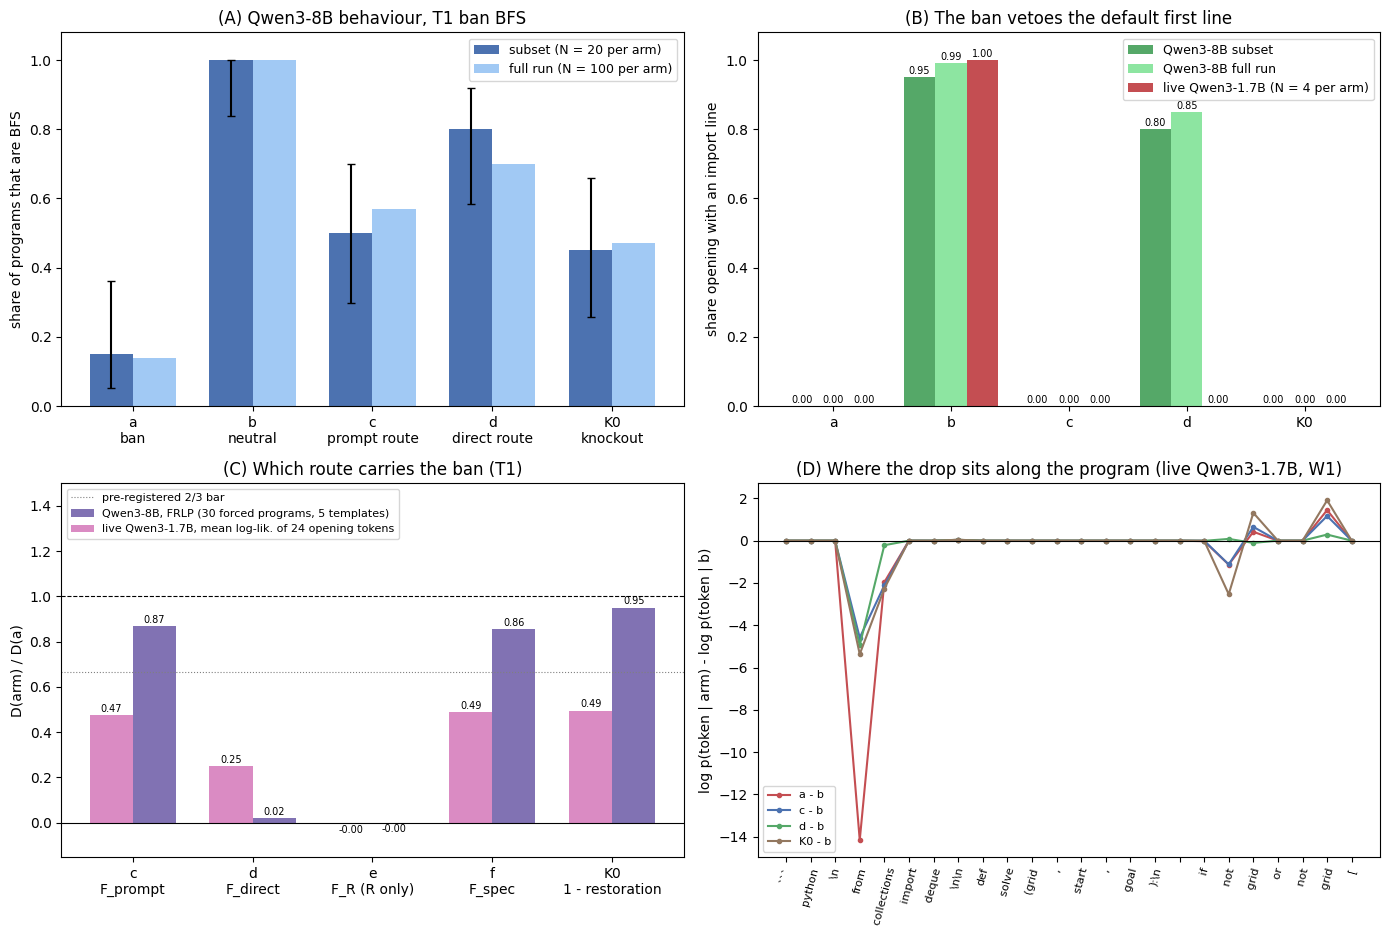

                          live small model (demo) Qwen3-8B, demo subset / re-applied rule                   Qwen3-8B, full run
F_prompt (T1)                            0.474432                                     n/a                             0.869766
F_direct (T1)                            0.250966                                     n/a                             0.018595
F_R (T1)                                -0.002112                                     n/a                            -0.000125
F_spec (T1)                              0.488232                                     n/a                             0.855715
import-first share, arm b                     1.0                                    0.95                                 0.99
import-first share, arm a                     0.0                                     0.0                                  0.0
C2 branch                                   MIXED     DECIDED_BEFORE_WRITING_prompt_route  DECIDED_BEFORE_WRITI

In [23]:
arms5 = ["a", "b", "c", "d", "K0"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))
x = np.arange(len(arms5))

# (A) banned share, Qwen3-8B
ax = axes[0, 0]
sub = [b_demo[a]["banned_share"] for a in "abcd"] + [k_demo["share"]]
lo = [b_demo[a]["banned_ci"][0] for a in "abcd"] + [k_demo["wilson_ci"][0]]
hi = [b_demo[a]["banned_ci"][1] for a in "abcd"] + [k_demo["wilson_ci"][1]]
full = [b_full[a]["banned_share"] for a in "abcd"] + [k_full["share"]]
ax.bar(x - 0.18, sub, 0.36, yerr=[np.subtract(sub, lo), np.subtract(hi, sub)], capsize=3, color="#4C72B0",
       label=f"subset (N = {b_demo['a']['n']} per arm)")
ax.bar(x + 0.18, full, 0.36, color="#A1C9F4", label="full run (N = 100 per arm)")
ax.set_xticks(x, ["a\nban", "b\nneutral", "c\nprompt route", "d\ndirect route", "K0\nknockout"])
ax.set_ylabel("share of programs that are BFS"); ax.set_ylim(0, 1.08)
ax.set_title("(A) Qwen3-8B behaviour, T1 ban BFS"); ax.legend(loc="upper right", fontsize=9)

# (B) import-first opening line
ax = axes[0, 1]
series = [("Qwen3-8B subset", [o_demo[a]["share_import_opening"] for a in arms5], "#55A868"),
          ("Qwen3-8B full run", [o_full[a]["share_import_opening"] for a in arms5], "#8DE5A1")]
if LIVE:
    series.append((f"live {MODEL_ID.split('/')[-1]} (N = {len(LIVE_STREAMS) * len(LIVE_TEMPLATES)} per arm)",
                   [LIVE["import_share"].get(a, np.nan) for a in arms5], "#C44E52"))
wd = 0.8 / len(series)
for i, (lab, vals, col) in enumerate(series):
    cont = ax.bar(x - 0.4 + wd * (i + 0.5), vals, wd, color=col, label=lab)
    ax.bar_label(cont, labels=[f"{v:.2f}" if np.isfinite(v) else "" for v in vals], fontsize=7, padding=1)
ax.set_xticks(x, ["a", "b", "c", "d", "K0"]); ax.set_ylim(0, 1.08)
ax.set_ylabel("share opening with an import line"); ax.set_title("(B) The ban vetoes the default first line")
ax.legend(loc="upper right", fontsize=9)

# (C) route fractions D(arm)/D(a)
ax = axes[1, 0]
fr_arms = ["c", "d", "e", "f", "K0"]
D8 = rf["per_task"]["t1"]["D"]
f8 = [D8[a] / D8["a"] for a in fr_arms]
cont = ax.bar(np.arange(5) + 0.18, f8, 0.36, color="#8172B3", label="Qwen3-8B, FRLP (30 forced programs, 5 templates)")
ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=1)
fl = []
if LIVE:
    fl = [LIVE["D"][a] / LIVE["D"]["a"] for a in fr_arms]
    cont = ax.bar(np.arange(5) - 0.18, fl, 0.36, color="#DA8BC3",
                  label=f"live {MODEL_ID.split('/')[-1]}, mean log-lik. of {N_SCORE_TOKENS} opening tokens")
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=1)
ax.set_ylim(min(-0.15, min(f8 + fl) - 0.15), max(1.5, max(f8 + fl) + 0.35))
ax.axhline(1, color="k", lw=0.8, ls="--"); ax.axhline(0, color="k", lw=0.8)
ax.axhline(THRESHOLDS["F_confirm"], color="grey", lw=0.8, ls=":", label="pre-registered 2/3 bar")
ax.set_xticks(np.arange(5), ["c\nF_prompt", "d\nF_direct", "e\nF_R (R only)", "f\nF_spec", "K0\n1 - restoration"])
ax.set_ylabel("D(arm) / D(a)"); ax.set_title("(C) Which route carries the ban (T1)"); ax.legend(fontsize=8, loc="upper left")

# (D) per-token localisation, live model
ax = axes[1, 1]
if LIVE:
    w0 = LIVE_TEMPLATES[0]
    toks = LIVE_SCORES["tokens"][f"{w0}|0"]
    ref_lp = LIVE_SCORES["tok_lp"][f"b|{w0}|0"]
    for a, col in (("a", "#C44E52"), ("c", "#4C72B0"), ("d", "#55A868"), ("K0", "#937860")):
        ax.plot(np.arange(len(toks)), LIVE_SCORES["tok_lp"][f"{a}|{w0}|0"] - ref_lp, marker="o", ms=3, color=col,
                label=f"{a} - b")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(np.arange(len(toks)), [repr(s)[1:-1] for s in toks], rotation=75, fontsize=8)
    ax.set_ylabel("log p(token | arm) - log p(token | b)")
    ax.set_title(f"(D) Where the drop sits along the program (live {MODEL_ID.split('/')[-1]}, {w0})")
    ax.legend(fontsize=8)
else:
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "demo_summary.png", dpi=120)
plt.show()

summary = pd.DataFrame({
    "live small model (demo)": [LIVE["F"]["F_prompt"] if LIVE else None, LIVE["F"]["F_direct"] if LIVE else None,
                                LIVE["F"]["F_R"] if LIVE else None, LIVE["F"]["F_spec"] if LIVE else None,
                                LIVE["import_share"].get("b") if LIVE else None, LIVE["import_share"].get("a") if LIVE else None,
                                LIVE["branch"]["branch"] if LIVE else None],
    "Qwen3-8B, demo subset / re-applied rule": ["n/a", "n/a", "n/a", "n/a", o_demo["b"]["share_import_opening"],
                                               o_demo["a"]["share_import_opening"], c2_rows[-1]["branch (re-applied)"]],
    "Qwen3-8B, full run": [rf["per_task"]["t1"]["F_prompt"], rf["per_task"]["t1"]["F_direct"], rf["per_task"]["t1"]["F_R"],
                           rf["per_task"]["t1"]["F_spec"], o_full["b"]["share_import_opening"],
                           o_full["a"]["share_import_opening"], pooled_ref["branch"]["branch"]],
}, index=["F_prompt (T1)", "F_direct (T1)", "F_R (T1)", "F_spec (T1)", "import-first share, arm b",
          "import-first share, arm a", "C2 branch"])
print(summary.to_string())
print("\nstage times of this notebook run:")
for r in read_jsonl(STAGE_LOG):
    print(f"  {r['stage']:<12} {r['seconds']:>7.1f} s")

## Reading the demo, and running the full experiment

**What the stored-sample analysis reproduces (Qwen3-8B, T1).** On the 100-sample subset (N = 20 per arm), the
pre-registered behaviour code gives the full-run picture:
- The ban drops BFS from 1.00 to 0.15. The matched CRN pairs flip in one direction only: 17 of 20 pairs are banned
  under b alone, none under a alone.
- The prompt-route arm c (0.50) and the direct-route arm d (0.80) each keep part of the effect. Behaviourally, T1 is
  mixed, as in the full run.
- No program opens with an import line under the ban, arm c or K0, while arm d keeps it (0.80).

The frozen decision rules, re-applied to the stored FRLP numbers, give *DECIDED BEFORE WRITING (prompt route)* for both
tasks and pooled, and ROBUST. C5 comes out PARTIAL (Holm p = 0.0006) and the decommitment axis NULL. The U9 estimator
checks reproduce the stored result exactly.

**What the live run saved in this notebook shows (Qwen3-1.7B, template W1, 4 CRN streams, 4 programs × 24 tokens).**
These numbers belong to the small model, not to Qwen3-8B. They show the machinery at work:
- The re-tokenised prompts are identical to the frozen Qwen3-8B prompts, and U3 passes: a spliced cache scores
  bit-identically to the unspliced one.
- With the same uniforms, the model opens with an import line (`from collections import deque` in 3 of 4) under the
  neutral twin, and with `def solve` under the ban, both route arms and K0 (panel B).
- The log-likelihood drop sits on the first code token, where `from` competes with `def`, not on the signature token
  `deque` (panel D).
- R alone carries nothing (`F_R ≈ 0`), and the task-spec states carry as much as the prompt route (`F_spec` 0.49
  against `F_prompt` 0.47). This is the same pattern as in Qwen3-8B.
- Unlike Qwen3-8B, the small model's direct route also carries part of the drop (`F_direct` 0.25) and also vetoes the
  import line. The frozen rule therefore calls the small model MIXED, not prompt-route.

**Full run.** This needs the repository folder `round-2/experiment-8/src`, one 24 GB GPU and about 70 GPU-minutes:

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r requirements.lock.txt
.venv/bin/python method.py s0 s1 s2          # snapshot + labeller check, prompts, forced programs (GPU for s2)
.venv/bin/python method.py prereg            # hash-commit the decision rules before any arm is scored
./run_gpu_chain.sh                           # tests -> s4 -> s5 (+ s4label) -> s6 -> s7 -> s8
.venv/bin/python method.py s8 s9             # analysis + method_out.json + figures
```

To move this notebook toward the original scale, set the config cell to its commented values:
- `MODEL_ID = "Qwen/Qwen3-8B"` with `DTYPE = "bfloat16"` on a GPU;
- `LIVE_TEMPLATES = W1-W5` and `LIVE_STREAMS = 0..19`;
- `N_NEW_TOKENS = 1024`, and whole programs.